cuda
적용된 폰트: ['Malgun Gothic']


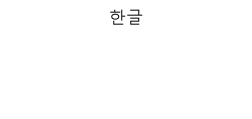

In [1]:
import os, time, copy
import numpy as np
import matplotlib.pyplot as plt
from glob import glob
from PIL import Image
from tqdm.auto import tqdm
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, random_split, Subset, DataLoader
from torchvision import datasets, transforms

torch.manual_seed(42)
np.random.seed(42)
# [NEW] 01~07.ipynb에 없는 설정: cudnn 연산의 비결정성을 줄여 재현성을 높인다
# (완전한 재현을 보장하지는 않지만, 같은 코드를 여러 번 실행했을 때 관찰된 val/test 성능 편차를 줄이기 위함)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

import platform
from matplotlib import font_manager

system = platform.system()
if system == 'Windows':
    # Windows는 맑은 고딕이 기본 내장되어 있어 설치 없이 바로 사용 가능
    plt.rc('font', family='Malgun Gothic')
elif system == 'Darwin':
    # macOS 기본 내장 한글 폰트
    plt.rc('font', family='AppleGothic')
else:
    # Colab 등 Linux: 위 셀에서 설치한 나눔고딕을 등록
    font_dir = '/usr/share/fonts/truetype/nanum'
    font_files = font_manager.findSystemFonts(fontpaths=font_dir)
    for fpath in font_files:
        font_manager.fontManager.addfont(fpath)
    plt.rc('font', family='NanumGothic')

plt.rcParams['axes.unicode_minus'] = False

# 설정한 폰트가 실제로 잡혔는지 확인
print('적용된 폰트:', plt.rcParams['font.family'])
plt.figure(figsize=(3,1))
plt.title('한글')
plt.axis('off')
plt.show()

# 쓰레기 이미지 12종 분류 (Garbage Classification)

- **목표**: `garbage_classification/` 폴더의 쓰레기 이미지(12개 클래스, 총 15,515장)를 분류하는 CNN 모델을 베이스라인부터 전이학습까지 비교·구현한다.
- **타겟**: 12개 폐기물 클래스 다중분류 (`battery`, `biological`, `brown-glass`, `cardboard`, `clothes`, `green-glass`, `metal`, `paper`, `plastic`, `shoes`, `trash`, `white-glass`)
- **성공 기준**: Accuracy 단독이 아니라 macro F1 / macro Recall 기준으로 베이스라인 CNN 대비 전이학습 모델의 개선 여부를 확인한다.
- **주의사항**: 클래스별 이미지 수 불균형(최대 `clothes` 5,325장 vs 최소 `brown-glass` 607장, 약 8.8배)이 있으므로 클래스 가중치를 적용하고, Confusion Matrix로 클래스별 오분류 패턴을 확인한다.

## 1. EDA — 클래스 분포

클래스 수: 12개, 전체 이미지 수: 15515장
battery     :   945장
biological  :   985장
brown-glass :   607장
cardboard   :   891장
clothes     :  5325장
green-glass :   629장
metal       :   769장
paper       :  1050장
plastic     :   865장
shoes       :  1977장
trash       :   697장
white-glass :   775장


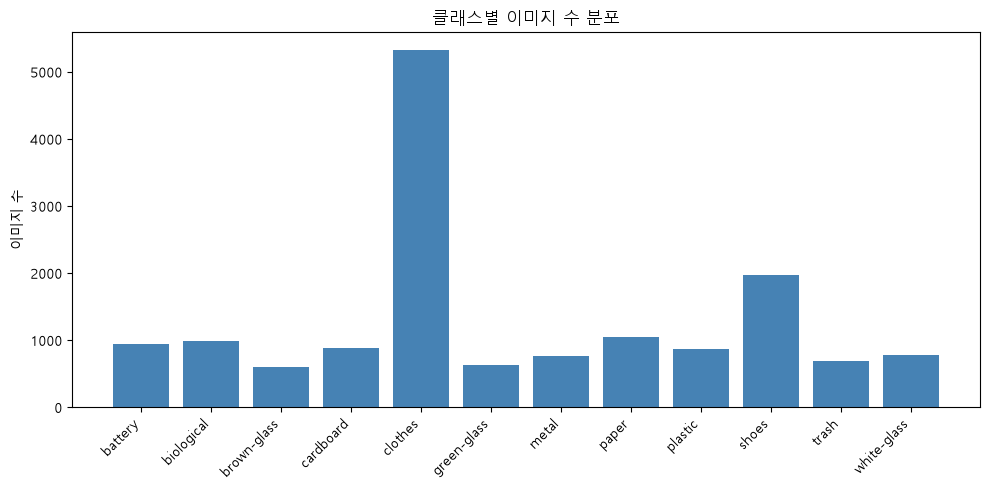

최다: clothes(5325장) / 최소: brown-glass(607장) / 비율: 8.77배 -> 불균형 있음, macro 지표 + 클래스 가중치 필요


In [2]:
data_dir = './garbage_classification'
class_names = sorted(os.listdir(data_dir))
class_counts = {c: len(glob(os.path.join(data_dir, c, '*.jpg'))) for c in class_names}

print(f'클래스 수: {len(class_names)}개, 전체 이미지 수: {sum(class_counts.values())}장')
for c, n in class_counts.items():
    print(f'{c:12s}: {n:5d}장')

plt.figure(figsize=(10, 5))
plt.bar(class_counts.keys(), class_counts.values(), color='steelblue')
plt.xticks(rotation=45, ha='right')
plt.ylabel('이미지 수')
plt.title('클래스별 이미지 수 분포')
plt.tight_layout()
plt.show()

max_c = max(class_counts, key=class_counts.get)
min_c = min(class_counts, key=class_counts.get)
print(f'최다: {max_c}({class_counts[max_c]}장) / 최소: {min_c}({class_counts[min_c]}장) '
      f'/ 비율: {class_counts[max_c] / class_counts[min_c]:.2f}배 -> 불균형 있음, macro 지표 + 클래스 가중치 필요')

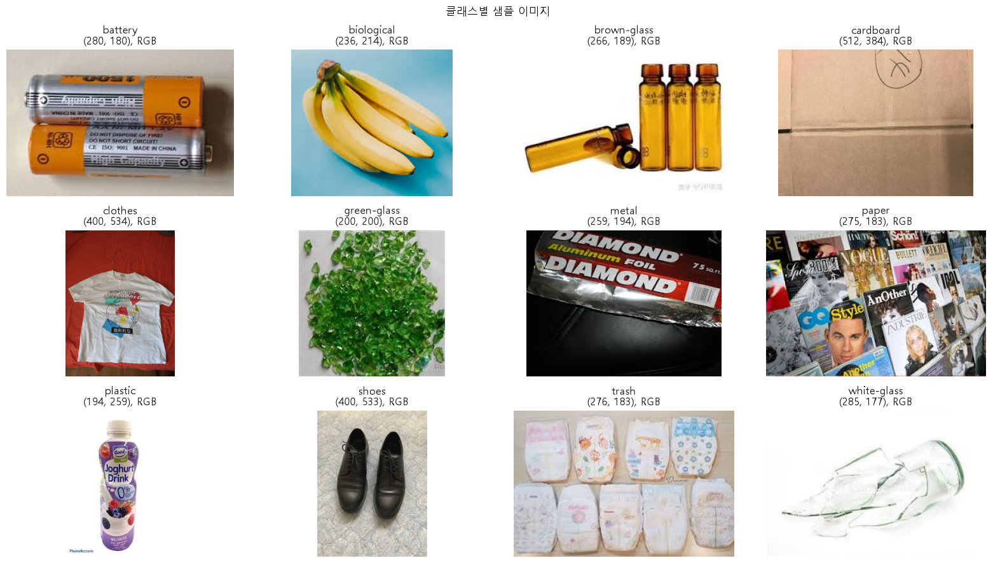

In [3]:
# 클래스별 샘플 이미지 확인
plt.figure(figsize=(16, 9))
for i, c in enumerate(class_names):
    img_path = glob(os.path.join(data_dir, c, '*.jpg'))[0]
    img = Image.open(img_path)
    plt.subplot(3, 4, i + 1)
    plt.imshow(img)
    plt.title(f'{c}\n{img.size}, {img.mode}')
    plt.axis('off')
plt.suptitle('클래스별 샘플 이미지')
plt.tight_layout()
plt.show()

In [4]:
# 전체 이미지 크기/색상모드/손상 여부 점검
from collections import Counter

all_files = [(c, f) for c in class_names for f in glob(os.path.join(data_dir, c, '*.jpg'))]
print(f'전체 파일 수: {len(all_files)}')

sizes, modes, corrupted = [], [], []
for c, f in tqdm(all_files, desc='이미지 검사'):
    try:
        img = Image.open(f)
        img.load()
        sizes.append(img.size)
        modes.append(img.mode)
    except Exception as e:
        corrupted.append((f, str(e)))

widths, heights = zip(*sizes)
print(f'손상된 파일 수: {len(corrupted)}')
print(f'가로 크기 범위: {min(widths)} ~ {max(widths)}')
print(f'세로 크기 범위: {min(heights)} ~ {max(heights)}')
print(f'색상 모드 분포: {dict(Counter(modes))}')
print('-> 이미지 크기가 파일마다 제각각이므로 Resize 필요, RGB 외 모드가 있다면 변환 필요')

전체 파일 수: 15515


이미지 검사:   0%|          | 0/15515 [00:00<?, ?it/s]

손상된 파일 수: 0
가로 크기 범위: 51 ~ 888
세로 크기 범위: 100 ~ 936
색상 모드 분포: {'RGB': 15481, 'P': 34}
-> 이미지 크기가 파일마다 제각각이므로 Resize 필요, RGB 외 모드가 있다면 변환 필요


## 2. 데이터 분할 및 전처리

- **로드 방식**: `torchvision.datasets.ImageFolder` — 폴더명이 곧 라벨이라 별도 `Dataset` 구현 없이 바로 사용 가능.
- **분할**: 클래스별 70/15/15 (`stratify` 목적) train/val/test, `random_state=42` 고정. 데이터 규모(15,515장)와 학습 비용을 고려해 고정 분할을 사용하고 StratifiedKFold는 쓰지 않는다.
- **리사이즈**: 128x128 — 파일마다 크기가 제각각이라 통일 필요, 베이스라인/전이학습 모두 같은 입력 크기로 학습 비용을 통제하기 위해 224보다 작은 128을 선택.
- **정규화 통계**: ImageNet mean/std — 전이학습(EfficientNetV2-S, ImageNet 사전학습) 백본과 베이스라인 CNN이 **같은 전처리**를 공유해야 하므로(모델 일관성 규칙) 두 모델 모두 ImageNet 통계로 정규화한다.
- **train 전용 증강**: `RandomHorizontalFlip`, `RandomRotation(15)`, `ColorJitter(brightness=0.2, contrast=0.2)` — 쓰레기 사진은 촬영 각도/좌우가 고정되어 있지 않고 조명 차이가 있어 적용. 다만 유리병 형태 등 모양 정보가 중요하므로 과도한 기하 왜곡(`RandomAffine`의 큰 이동/스케일 등)은 넣지 않는다.
- **Data Leakage 방지**: 정규화 통계는 고정된 ImageNet 값을 쓰므로 train 통계 유출 문제가 없고, 증강은 train에만 적용한다.

### 2-0. 중복 이미지 반영 (2.ipynb 결과)

`2.ipynb`에서 찾고 사람이 직접 확인까지 마친 중복 결과를 분할에 반영한다(자세한 과정은 `2.ipynb`, `2_notes.md`, `PROGRESS.md` 참고).

- **완전 동일(byte-identical) 중복**: 같은 클래스 안에서 중복이면 1장만 남기고 나머지는 제외한다. 클래스가 서로 다른 3개 그룹(`metal`↔`white-glass`, `plastic`↔`white-glass` x2)은 어느 라벨이 맞는지 판단할 근거가 없어 **두 장 다 제외**한다(가정: 라벨이 불확실한 소수 이미지(6장)는 포함시키는 것보다 빼는 쪽이 안전하다).
- **근접 중복(리사이즈/재압축/워터마크만 다름)**: 파일 자체는 지우지 않되, 같은 그룹의 파일들이 train/val/test 중 **한 곳에만** 들어가도록 덩어리(cluster) 단위로 분할한다 — 그렇지 않으면 같은 사진이 train과 val/test에 동시에 들어가는 data leakage가 생겨 검증/테스트 점수가 실제보다 부풀려질 수 있다.

In [5]:
# 완전 동일 중복 - 같은 클래스(15그룹): 1장만 남김
exact_dup_groups_same_class = [
    [('clothes', 'clothes2051.jpg'), ('clothes', 'clothes5234.jpg')],
    [('green-glass', 'green-glass231.jpg'), ('green-glass', 'green-glass530.jpg')],
    [('green-glass', 'green-glass285.jpg'), ('green-glass', 'green-glass555.jpg')],
    [('green-glass', 'green-glass292.jpg'), ('green-glass', 'green-glass443.jpg')],
    [('green-glass', 'green-glass336.jpg'), ('green-glass', 'green-glass554.jpg')],
    [('green-glass', 'green-glass349.jpg'), ('green-glass', 'green-glass461.jpg')],
    [('green-glass', 'green-glass388.jpg'), ('green-glass', 'green-glass459.jpg')],
    [('green-glass', 'green-glass403.jpg'), ('green-glass', 'green-glass564.jpg')],
    [('green-glass', 'green-glass413.jpg'), ('green-glass', 'green-glass517.jpg'), ('green-glass', 'green-glass563.jpg')],
    [('green-glass', 'green-glass422.jpg'), ('green-glass', 'green-glass482.jpg')],
    [('green-glass', 'green-glass424.jpg'), ('green-glass', 'green-glass561.jpg')],
    [('green-glass', 'green-glass449.jpg'), ('green-glass', 'green-glass565.jpg')],
    [('green-glass', 'green-glass471.jpg'), ('green-glass', 'green-glass544.jpg')],
    [('green-glass', 'green-glass476.jpg'), ('green-glass', 'green-glass492.jpg')],
    [('green-glass', 'green-glass583.jpg'), ('green-glass', 'green-glass592.jpg')],
]

# 완전 동일 중복 - 클래스가 다름(3그룹, 라벨 불일치): 전부 제외
cross_class_exact_dup_groups = [
    [('metal', 'metal459.jpg'), ('white-glass', 'white-glass412.jpg')],
    [('plastic', 'plastic159.jpg'), ('white-glass', 'white-glass129.jpg')],
    [('plastic', 'plastic556.jpg'), ('white-glass', 'white-glass761.jpg')],
]

# 근접 중복(42그룹, 2.ipynb에서 수동 검토까지 완료): 같은 split에만 배치
near_dup_groups = [
    [('battery', 'battery268.jpg'), ('battery', 'battery343.jpg')],
    [('battery', 'battery63.jpg'), ('battery', 'battery833.jpg')],
    [('battery', 'battery759.jpg'), ('battery', 'battery945.jpg')],
    [('biological', 'biological401.jpg'), ('biological', 'biological709.jpg')],
    [('biological', 'biological402.jpg'), ('biological', 'biological781.jpg')],
    [('biological', 'biological410.jpg'), ('biological', 'biological865.jpg')],
    [('brown-glass', 'brown-glass19.jpg'), ('brown-glass', 'brown-glass439.jpg')],
    [('clothes', 'clothes2051.jpg'), ('clothes', 'clothes5234.jpg')],
    [('clothes', 'clothes5095.jpg'), ('clothes', 'clothes536.jpg')],
    [('green-glass', 'green-glass190.jpg'), ('green-glass', 'green-glass46.jpg')],
    [('green-glass', 'green-glass2.jpg'), ('green-glass', 'green-glass292.jpg'), ('green-glass', 'green-glass443.jpg')],
    [('green-glass', 'green-glass228.jpg'), ('green-glass', 'green-glass433.jpg')],
    [('green-glass', 'green-glass231.jpg'), ('green-glass', 'green-glass530.jpg')],
    [('green-glass', 'green-glass285.jpg'), ('green-glass', 'green-glass555.jpg')],
    [('green-glass', 'green-glass336.jpg'), ('green-glass', 'green-glass554.jpg')],
    [('green-glass', 'green-glass349.jpg'), ('green-glass', 'green-glass461.jpg')],
    [('green-glass', 'green-glass388.jpg'), ('green-glass', 'green-glass459.jpg')],
    [('green-glass', 'green-glass403.jpg'), ('green-glass', 'green-glass564.jpg')],
    [('green-glass', 'green-glass413.jpg'), ('green-glass', 'green-glass517.jpg'), ('green-glass', 'green-glass563.jpg')],
    [('green-glass', 'green-glass422.jpg'), ('green-glass', 'green-glass482.jpg')],
    [('green-glass', 'green-glass424.jpg'), ('green-glass', 'green-glass561.jpg')],
    [('green-glass', 'green-glass449.jpg'), ('green-glass', 'green-glass565.jpg')],
    [('green-glass', 'green-glass451.jpg'), ('green-glass', 'green-glass488.jpg')],
    [('green-glass', 'green-glass471.jpg'), ('green-glass', 'green-glass544.jpg')],
    [('green-glass', 'green-glass476.jpg'), ('green-glass', 'green-glass492.jpg')],
    [('green-glass', 'green-glass583.jpg'), ('green-glass', 'green-glass592.jpg')],
    [('metal', 'metal459.jpg'), ('white-glass', 'white-glass412.jpg')],
    [('metal', 'metal590.jpg'), ('metal', 'metal745.jpg')],
    [('plastic', 'plastic159.jpg'), ('white-glass', 'white-glass129.jpg')],
    [('plastic', 'plastic467.jpg'), ('plastic', 'plastic506.jpg')],
    [('plastic', 'plastic556.jpg'), ('white-glass', 'white-glass761.jpg')],
    [('shoes', 'shoes1049.jpg'), ('shoes', 'shoes1390.jpg')],
    [('shoes', 'shoes1065.jpg'), ('shoes', 'shoes1482.jpg'), ('shoes', 'shoes651.jpg')],
    [('shoes', 'shoes1095.jpg'), ('shoes', 'shoes777.jpg')],
    [('shoes', 'shoes1128.jpg'), ('shoes', 'shoes615.jpg')],
    [('shoes', 'shoes1227.jpg'), ('shoes', 'shoes1368.jpg')],
    [('shoes', 'shoes29.jpg'), ('shoes', 'shoes621.jpg')],
    [('trash', 'trash238.jpg'), ('trash', 'trash301.jpg')],
    [('trash', 'trash254.jpg'), ('trash', 'trash559.jpg')],
    [('trash', 'trash683.jpg'), ('trash', 'trash688.jpg')],
    [('white-glass', 'white-glass300.jpg'), ('white-glass', 'white-glass472.jpg')],
    [('white-glass', 'white-glass674.jpg'), ('white-glass', 'white-glass688.jpg')],
]

In [6]:
# 클래스별 70/15/15 stratified 분할 (라벨만 필요하므로 transform 없이 ImageFolder 생성)
label_only = datasets.ImageFolder(data_dir)
print(label_only.class_to_idx)
assert label_only.classes == class_names

from collections import defaultdict

targets = np.array(label_only.targets)
key_to_idx = {(class_names[cls], os.path.basename(path)): i
              for i, (path, cls) in enumerate(label_only.samples)}

# 1) 완전 동일 중복 중 라벨이 다른 것 -> 두 장 다 제외
excluded_idx = set()
for group in cross_class_exact_dup_groups:
    for key in group:
        excluded_idx.add(key_to_idx[key])

# 2) 완전 동일 중복 중 같은 클래스인 것 -> 파일명 기준 첫 번째만 남기고 나머지 제외
for group in exact_dup_groups_same_class:
    keep, *rest = sorted(group, key=lambda x: x[1])
    for key in rest:
        excluded_idx.add(key_to_idx[key])

print(f'중복으로 제외한 파일 수: {len(excluded_idx)}장 '
      f'(라벨 불일치 {sum(len(g) for g in cross_class_exact_dup_groups)}장 + '
      f'완전 동일 중복 여분 {sum(len(g) - 1 for g in exact_dup_groups_same_class)}장)')

# 3) 근접 중복 그룹은 파일을 지우지 않고, (제외되지 않은) 같은 그룹 파일들을 하나의 덩어리로 묶는다
# [NEW] 01~07.ipynb에 없는 기법: Union-Find로 근접 중복 파일들을 같은 분할 단위(덩어리)로 묶음
# (2.ipynb에서 이미 같은 방식을 썼던 것과 동일한 이유 - 같은 사진이 train/val/test로 쪼개지는 걸 막기 위함)
class UnionFind:
    def __init__(self, n):
        self.parent = list(range(n))
    def find(self, x):
        while self.parent[x] != x:
            self.parent[x] = self.parent[self.parent[x]]
            x = self.parent[x]
        return x
    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra != rb:
            self.parent[ra] = rb

uf = UnionFind(len(label_only.samples))
for group in near_dup_groups:
    members = [key_to_idx[key] for key in group if key_to_idx[key] not in excluded_idx]
    for m in members[1:]:
        uf.union(members[0], m)

remaining_idx = [i for i in range(len(label_only.samples)) if i not in excluded_idx]
clusters_by_root = defaultdict(list)
for i in remaining_idx:
    clusters_by_root[uf.find(i)].append(i)
clusters = list(clusters_by_root.values())

n_multi = sum(1 for c in clusters if len(c) > 1)
print(f'제외 후 남은 파일 수: {len(remaining_idx)}장, 분할 단위(덩어리) 수: {len(clusters)}개 '
      f'(이 중 {n_multi}개는 근접 중복 2장 이상을 하나로 묶은 덩어리)')

# 4) 클래스별 70/15/15 분할을 '개별 파일'이 아니라 '덩어리(cluster)' 단위로 수행
#    (덩어리 안의 근접 중복 파일들이 서로 다른 split으로 갈라지지 않도록)
train_idx, val_idx, test_idx = [], [], []
rng = np.random.RandomState(42)
for c in range(len(class_names)):
    c_clusters = [cluster for cluster in clusters if targets[cluster[0]] == c]
    rng.shuffle(c_clusters)

    n = sum(len(cluster) for cluster in c_clusters)
    n_train = int(n * 0.7)
    n_val = int(n * 0.15)

    cum = 0
    for cluster in c_clusters:
        if cum < n_train:
            train_idx += cluster
        elif cum < n_train + n_val:
            val_idx += cluster
        else:
            test_idx += cluster
        cum += len(cluster)

print(f'train {len(train_idx)} / val {len(val_idx)} / test {len(test_idx)} '
      f'(총 {len(train_idx) + len(val_idx) + len(test_idx)})')

{'battery': 0, 'biological': 1, 'brown-glass': 2, 'cardboard': 3, 'clothes': 4, 'green-glass': 5, 'metal': 6, 'paper': 7, 'plastic': 8, 'shoes': 9, 'trash': 10, 'white-glass': 11}
중복으로 제외한 파일 수: 22장 (라벨 불일치 6장 + 완전 동일 중복 여분 16장)
제외 후 남은 파일 수: 15493장, 분할 단위(덩어리) 수: 15467개 (이 중 25개는 근접 중복 2장 이상을 하나로 묶은 덩어리)
train 10838 / val 2318 / test 2337 (총 15493)


In [7]:
# 클래스 불균형 대응: train 기준 1/count 클래스 가중치 (CrossEntropyLoss weight로 사용)
train_targets = targets[train_idx]
counts = np.array([np.sum(train_targets == c) for c in range(len(class_names))])
class_weight_np = (1.0 / counts) * (counts.sum() / len(counts))
class_weights = torch.tensor(class_weight_np, dtype=torch.float32, device=device)

for c, w in zip(class_names, class_weight_np):
    print(f'{c:12s}: weight={w:.3f}')

battery     : weight=1.366


biological  : weight=1.311
brown-glass : weight=2.130
cardboard   : weight=1.450
clothes     : weight=0.242
green-glass : weight=2.105
metal       : weight=1.682
paper       : weight=1.229
plastic     : weight=1.495
shoes       : weight=0.653
trash       : weight=1.855
white-glass : weight=1.673


### 2-1. 전처리 · 불균형 대응 방식 비교 (val 기준)

지금까지는 `Resize((IMAGE_SIZE, IMAGE_SIZE))`로 원본 비율을 무시하고 정사각형으로 강제 리사이즈했고, 클래스 불균형은 `CrossEntropyLoss`의 클래스 가중치로만 대응했다. 아래 두 가지 대안을 추가로 비교한다.

1. **리사이즈 방식**: (A) 정사각형으로 찌그러뜨리는 지금 방식 vs (B) 짧은 변 기준으로 비율을 유지해 리사이즈한 뒤 크롭하는 방식(병 모양처럼 형태가 중요한 클래스의 왜곡을 줄이기 위함).
2. **불균형 대응**: (A) loss에 클래스 가중치를 주는 지금 방식 vs (B) `WeightedRandomSampler`로 학습 배치 자체에서 소수 클래스를 더 자주 뽑는 방식.

2x2 = 4가지 조합을 **전이학습 모델(EfficientNetV2-S, freeze)만으로 짧게(3 epoch)** 학습해 val_macro_f1로 비교한다 — 베이스라인 CNN까지 포함하면 시간이 2배 이상 들고, 이미 검증에서 전이학습 모델이 뚜렷하게 앞서므로 실제로 채택될 모델 기준으로 비교하는 것으로 범위를 좁혔다. 비교는 val로만 하고(`test_loader` 미사용), 결정된 설정을 노트북 전체(베이스라인 포함)가 공유한다(모델 일관성 규칙).

In [8]:
IMAGE_SIZE = 128
BATCH_SIZE = 64
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# (A) 정사각형으로 강제 리사이즈 (지금까지 쓰던 방식)
train_tf_squash = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)])

eval_tf_squash = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)])

# (B) 원본 비율을 유지한 채 짧은 변 기준으로 리사이즈 후 크롭
CROP_RESIZE = int(IMAGE_SIZE * 1.15)

train_tf_crop = transforms.Compose([
    transforms.Resize(CROP_RESIZE),
    transforms.RandomCrop(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)])

eval_tf_crop = transforms.Compose([
    transforms.Resize(CROP_RESIZE),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)])

In [9]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

@torch.no_grad()
def evaluate(model, loader, criterion=None):
    model.eval()
    losses, preds_all, trues_all = [], [], []

    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)

        if criterion is not None:
            losses.append(criterion(logits, yb).item() * len(yb))

        preds_all.append(logits.argmax(dim=1).cpu().numpy())
        trues_all.append(yb.cpu().numpy())

    preds = np.concatenate(preds_all)
    trues = np.concatenate(trues_all)
    report = classification_report(trues, preds, output_dict=True, zero_division=0)

    return {
        'loss': (sum(losses) / len(trues)) if criterion is not None else None,
        'accuracy': accuracy_score(trues, preds),
        'macro_f1': report['macro avg']['f1-score'],
        'macro_recall': report['macro avg']['recall'],
        'preds': preds,
        'trues': trues}

def train_model(model, train_loader, val_loader, epochs=8, lr=1e-3,
                class_weights=None, ckpt_path='best_model.pt', label='model',
                patience=5, use_scheduler=False, scheduler_patience=1):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    # 01~07.ipynb(02/04/06)에서 이미 쓰던 ReduceLROnPlateau 패턴 그대로 재사용 —
    # val_loss가 scheduler_patience epoch 동안 줄지 않으면 학습률을 0.1배로 낮춘다.
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.1, patience=scheduler_patience, min_lr=1e-7) if use_scheduler else None

    history = {k: [] for k in ['loss', 'val_loss', 'accuracy', 'val_accuracy',
                               'val_macro_f1', 'val_macro_recall']}
    best_f1 = -1.0
    epochs_no_improve = 0

    for epoch in range(1, epochs + 1):
        model.train()
        run_loss, run_correct, n = 0.0, 0, 0
        t0 = time.time()

        for xb, yb in tqdm(train_loader, desc=f'[{label}] Epoch {epoch}/{epochs}', leave=False):
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

            run_loss += loss.item() * len(yb)
            run_correct += (logits.argmax(dim=1) == yb).sum().item()
            n += len(yb)

        tr_loss, tr_acc = run_loss / n, run_correct / n
        m = evaluate(model, val_loader, criterion)
        if scheduler is not None:
            scheduler.step(m['loss'])

        history['loss'].append(tr_loss)
        history['val_loss'].append(m['loss'])
        history['accuracy'].append(tr_acc)
        history['val_accuracy'].append(m['accuracy'])
        history['val_macro_f1'].append(m['macro_f1'])
        history['val_macro_recall'].append(m['macro_recall'])

        if m['macro_f1'] > best_f1:
            best_f1 = m['macro_f1']
            epochs_no_improve = 0
            torch.save(model.state_dict(), ckpt_path)
        else:
            epochs_no_improve += 1

        lr_str = f' lr={optimizer.param_groups[0]["lr"]:.1e}' if use_scheduler else ''
        print(f'[{label}] Epoch {epoch}/{epochs} ({time.time() - t0:.1f}s) '
              f'train_loss={tr_loss:.4f} train_acc={tr_acc:.4f} '
              f'val_loss={m["loss"]:.4f} val_acc={m["accuracy"]:.4f} '
              f'val_macro_f1={m["macro_f1"]:.4f} val_macro_recall={m["macro_recall"]:.4f}{lr_str}')

        # [NEW] 01~07.ipynb에 없는 기법: 조기 종료(early stopping) — val_macro_f1이 patience epoch
        # 동안 개선되지 않으면 학습을 멈춘다. 01~07은 ReduceLROnPlateau의 patience로 학습률만
        # 줄였을 뿐 루프 자체를 중단하지는 않았는데, epoch 상한을 넉넉히 올린 대신 이미 수렴한
        # 모델에서 불필요한 반복 학습(+과적합 위험)을 줄이기 위해 추가한다.
        if epochs_no_improve >= patience:
            print(f'[{label}] val_macro_f1이 {patience} epoch 동안 개선되지 않아 '
                  f'{epoch}/{epochs} epoch에서 조기 종료')
            break

    return history

In [10]:
# 전이학습 모델: ImageNet 사전학습 EfficientNetV2-S, 백본 freeze (전처리 비교/최종 학습에 공용으로 사용)
from torchvision import models

class TransferModel(nn.Module):
    def __init__(self, num_classes=12, freeze=True):
        super().__init__()
        weights = models.EfficientNet_V2_S_Weights.IMAGENET1K_V1
        backbone = models.efficientnet_v2_s(weights=weights)
        self.features = backbone.features

        if freeze:
            for p in self.features.parameters():
                p.requires_grad = False

        self.pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(1280, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x).flatten(1)
        return self.fc(self.dropout(x))

def summarize(model, name='model'):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f'{name} - 전체 파라미터: {total:,} / 학습 파라미터: {trainable:,}')

summarize(TransferModel(num_classes=len(class_names), freeze=True), 'TransferModel (freeze)')

# 불균형 대응 (B): WeightedRandomSampler - 위에서 구한 클래스 가중치를 샘플 확률로 사용
from torch.utils.data import WeightedRandomSampler

sample_weights = class_weight_np[train_targets]
sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

def make_loaders(train_tf, eval_tf, use_sampler):
    train_full = datasets.ImageFolder(data_dir, transform=train_tf)
    eval_full = datasets.ImageFolder(data_dir, transform=eval_tf)

    train_set = Subset(train_full, train_idx)
    val_set = Subset(eval_full, val_idx)
    test_set = Subset(eval_full, test_idx)

    if use_sampler:
        train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, sampler=sampler)
    else:
        train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)
    test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)
    return train_set, val_set, test_set, train_loader, val_loader, test_loader

TransferModel (freeze) - 전체 파라미터: 20,192,860 / 학습 파라미터: 15,372


In [11]:
EPOCHS_ABLATION = 3

ablation_configs = [
    ('squash_weight', '정사각형 리사이즈 + 클래스가중치', train_tf_squash, eval_tf_squash, False, True),
    ('crop_weight', '비율유지 크롭 + 클래스가중치', train_tf_crop, eval_tf_crop, False, True),
    ('squash_sampler', '정사각형 리사이즈 + WeightedRandomSampler', train_tf_squash, eval_tf_squash, True, False),
    ('crop_sampler', '비율유지 크롭 + WeightedRandomSampler', train_tf_crop, eval_tf_crop, True, False),
]

ablation_results = {}
for key, label, tr_tf, ev_tf, use_sampler, use_class_weight in ablation_configs:
    _, _, _, tr_loader, va_loader, _ = make_loaders(tr_tf, ev_tf, use_sampler)

    model = TransferModel(num_classes=len(class_names), freeze=True)
    history = train_model(model, tr_loader, va_loader, epochs=EPOCHS_ABLATION, lr=5e-4,
                          class_weights=class_weights if use_class_weight else None,
                          ckpt_path=f'ablation_{key}.pt', label=label)
    ablation_results[key] = max(history['val_macro_f1'])  # 조기 종료/변동 대비 마지막 값 대신 최고값 사용

print(f'\n{"설정":45s}{"val_macro_f1":>14s}')
for key, label, *_ in ablation_configs:
    print(f'{label:45s}{ablation_results[key]:14.4f}')

best_key = max(ablation_results, key=ablation_results.get)
print(f'\n최고 val_macro_f1 설정: {[label for k, label, *_ in ablation_configs if k == best_key][0]}')

[정사각형 리사이즈 + 클래스가중치] Epoch 1/3:   0%|          | 0/170 [00:00<?, ?it/s]

[정사각형 리사이즈 + 클래스가중치] Epoch 1/3 (31.0s) train_loss=1.7079 train_acc=0.6109 val_loss=1.1315 val_acc=0.7567 val_macro_f1=0.6815 val_macro_recall=0.7002


[정사각형 리사이즈 + 클래스가중치] Epoch 2/3:   0%|          | 0/170 [00:00<?, ?it/s]

[정사각형 리사이즈 + 클래스가중치] Epoch 2/3 (32.8s) train_loss=1.1166 train_acc=0.7500 val_loss=0.8874 val_acc=0.7783 val_macro_f1=0.7171 val_macro_recall=0.7398


[정사각형 리사이즈 + 클래스가중치] Epoch 3/3:   0%|          | 0/170 [00:00<?, ?it/s]

[정사각형 리사이즈 + 클래스가중치] Epoch 3/3 (32.1s) train_loss=0.9641 train_acc=0.7605 val_loss=0.8321 val_acc=0.7817 val_macro_f1=0.7227 val_macro_recall=0.7456


... (14 outputs left out)

[비율유지 크롭 + WeightedRandomSampler] Epoch 2/3:   0%|          | 0/170 [00:00<?, ?it/s]

[비율유지 크롭 + WeightedRandomSampler] Epoch 2/3 (30.3s) train_loss=1.0463 train_acc=0.7106 val_loss=0.7706 val_acc=0.8184 val_macro_f1=0.7570 val_macro_recall=0.7707


[비율유지 크롭 + WeightedRandomSampler] Epoch 3/3:   0%|          | 0/170 [00:00<?, ?it/s]

[비율유지 크롭 + WeightedRandomSampler] Epoch 3/3 (31.1s) train_loss=0.9036 train_acc=0.7396 val_loss=0.6958 val_acc=0.8197 val_macro_f1=0.7604 val_macro_recall=0.7764

설정                                             val_macro_f1
정사각형 리사이즈 + 클래스가중치                                   0.7227
비율유지 크롭 + 클래스가중치                                     0.7523
정사각형 리사이즈 + WeightedRandomSampler                    0.7534
비율유지 크롭 + WeightedRandomSampler                      0.7604

최고 val_macro_f1 설정: 비율유지 크롭 + WeightedRandomSampler


In [12]:
# 위 비교에서 가장 좋았던 설정으로 노트북 전체(베이스라인 포함)가 쓸 train/val/test를 확정한다
config_lookup = {key: (label, tr_tf, ev_tf, use_sampler, use_class_weight)
                 for key, label, tr_tf, ev_tf, use_sampler, use_class_weight in ablation_configs}
best_label, train_tf, eval_tf, use_sampler_final, use_class_weight_final = config_lookup[best_key]

train_set, val_set, test_set, train_loader, val_loader, test_loader = make_loaders(
    train_tf, eval_tf, use_sampler_final)

print(f'최종 전처리/불균형 대응 설정: {best_label}')
print(len(train_set), len(val_set), len(test_set))

최종 전처리/불균형 대응 설정: 비율유지 크롭 + WeightedRandomSampler
10838 2318 2337


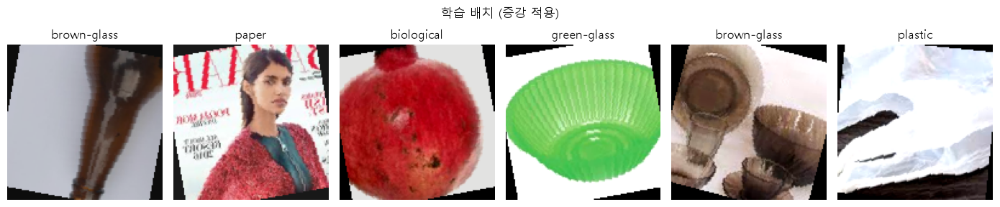

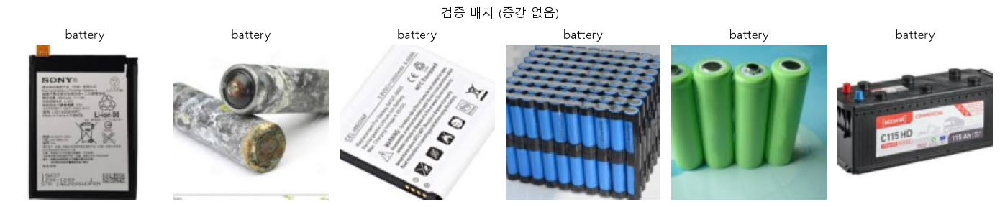

In [13]:
# 증강 적용 전후 비교: train(증강 적용) vs eval(증강 없음) 배치 시각화
def denormalize(t):
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (t.cpu() * std + mean).clamp(0, 1)

def show_batch(loader, title, num_images=6):
    images, labels = next(iter(loader))
    plt.figure(figsize=(14, 3))
    for i in range(num_images):
        plt.subplot(1, num_images, i + 1)
        plt.imshow(denormalize(images[i]).permute(1, 2, 0).numpy())
        plt.title(class_names[int(labels[i])])
        plt.axis('off')
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

show_batch(train_loader, '학습 배치 (증강 적용)')
show_batch(val_loader, '검증 배치 (증강 없음)')

## 3. 모델링 — 베이스라인 CNN vs 전이학습(EfficientNetV2-S, freeze/unfreeze)

- 다중분류(12종)이므로 `nn.CrossEntropyLoss` + `argmax` 예측을 기본 노선으로 사용한다.
- 비교는 **검증셋(val) 기준**으로만 하며(`test_loader`는 최종 평가 셀 1곳에서만 사용), macro F1/Recall을 `sklearn.metrics.classification_report`의 `output_dict=True` 결과에서 뽑아 사용한다.

(공용 함수 `evaluate`/`train_model`과 `TransferModel`은 위 2-1 전처리 비교에서 이미 정의했으므로 재사용한다.)
- 각 모델의 epoch 상한은 넉넉히 잡고(베이스라인 30 / freeze 20 / unfreeze 15), val_macro_f1 기준 조기 종료(early stopping, patience 3~5)로 실제 학습은 수렴 시점에 맞춰 자동으로 멈추게 했다.

In [14]:
# 베이스라인: 처음부터 학습하는 얕은 CNN
def conv_block(in_ch, out_ch):
    return [
        nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True)]

class BaselineCNN(nn.Module):
    def __init__(self, num_classes=12):
        super().__init__()
        self.features = nn.Sequential(
            *conv_block(3, 32), nn.MaxPool2d(2),
            *conv_block(32, 64), nn.MaxPool2d(2),
            *conv_block(64, 128), nn.MaxPool2d(2),
            *conv_block(128, 256), nn.MaxPool2d(2))
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes))

    def forward(self, x):
        return self.classifier(self.features(x))

def summarize(model, name='model'):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f'{name} - 전체 파라미터: {total:,} / 학습 파라미터: {trainable:,}')

summarize(BaselineCNN(num_classes=len(class_names)), 'BaselineCNN')

BaselineCNN - 전체 파라미터: 392,460 / 학습 파라미터: 392,460


In [15]:
EPOCHS_BASE = 30  # 조기 종료가 있으므로 상한을 넉넉히 잡는다

baseline_model = BaselineCNN(num_classes=len(class_names))
baseline_history = train_model(baseline_model, train_loader, val_loader,
                               epochs=EPOCHS_BASE, lr=1e-3, patience=5,
                               class_weights=class_weights if use_class_weight_final else None,
                               ckpt_path='best_baseline_cnn.pt', label='BaselineCNN')

[BaselineCNN] Epoch 1/30:   0%|          | 0/170 [00:00<?, ?it/s]

[BaselineCNN] Epoch 1/30 (27.4s) train_loss=1.6762 train_acc=0.4376 val_loss=1.7438 val_acc=0.4215 val_macro_f1=0.4177 val_macro_recall=0.5074


[BaselineCNN] Epoch 2/30:   0%|          | 0/170 [00:00<?, ?it/s]

[BaselineCNN] Epoch 2/30 (27.4s) train_loss=1.4521 train_acc=0.5121 val_loss=1.4553 val_acc=0.5035 val_macro_f1=0.4787 val_macro_recall=0.5437


[BaselineCNN] Epoch 3/30:   0%|          | 0/170 [00:00<?, ?it/s]

[BaselineCNN] Epoch 3/30 (27.4s) train_loss=1.3490 train_acc=0.5516 val_loss=1.3963 val_acc=0.5656 val_macro_f1=0.5349 val_macro_recall=0.5810


... (40 outputs left out)

[BaselineCNN] Epoch 24/30:   0%|          | 0/170 [00:00<?, ?it/s]

[BaselineCNN] Epoch 24/30 (27.7s) train_loss=0.8362 train_acc=0.7200 val_loss=0.8799 val_acc=0.7097 val_macro_f1=0.6750 val_macro_recall=0.7104


[BaselineCNN] Epoch 25/30:   0%|          | 0/170 [00:00<?, ?it/s]

[BaselineCNN] Epoch 25/30 (28.4s) train_loss=0.8326 train_acc=0.7262 val_loss=0.8300 val_acc=0.7166 val_macro_f1=0.6935 val_macro_recall=0.7313
[BaselineCNN] val_macro_f1이 5 epoch 동안 개선되지 않아 25/30 epoch에서 조기 종료


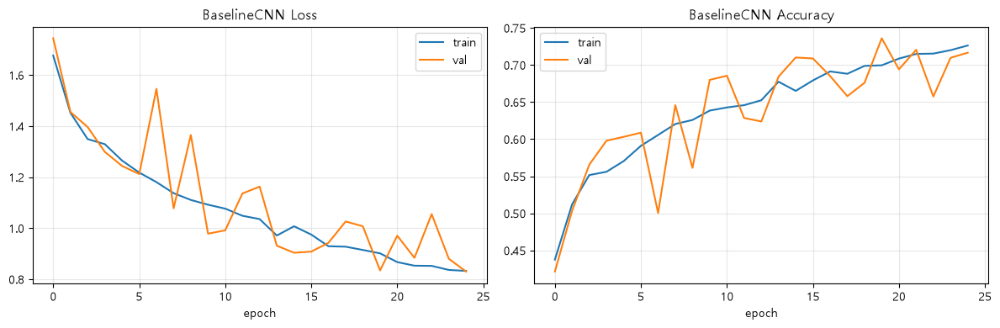

In [16]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(baseline_history['loss'], label='train')
plt.plot(baseline_history['val_loss'], label='val')
plt.title('BaselineCNN Loss')
plt.xlabel('epoch')
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(baseline_history['accuracy'], label='train')
plt.plot(baseline_history['val_accuracy'], label='val')
plt.title('BaselineCNN Accuracy')
plt.xlabel('epoch')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [17]:
EPOCHS_TRANSFER = 20  # 조기 종료가 있으므로 상한을 넉넉히 잡는다

transfer_model = TransferModel(num_classes=len(class_names), freeze=True)
transfer_history = train_model(transfer_model, train_loader, val_loader,
                               epochs=EPOCHS_TRANSFER, lr=5e-4, patience=4,
                               class_weights=class_weights if use_class_weight_final else None,
                               ckpt_path='best_transfer_model.pt', label='EfficientNetV2S(freeze)')

[EfficientNetV2S(freeze)] Epoch 1/20:   0%|          | 0/170 [00:00<?, ?it/s]

[EfficientNetV2S(freeze)] Epoch 1/20 (30.5s) train_loss=1.6148 train_acc=0.5732 val_loss=0.9761 val_acc=0.7951 val_macro_f1=0.7200 val_macro_recall=0.7291


[EfficientNetV2S(freeze)] Epoch 2/20:   0%|          | 0/170 [00:00<?, ?it/s]

[EfficientNetV2S(freeze)] Epoch 2/20 (30.8s) train_loss=1.0524 train_acc=0.7070 val_loss=0.7617 val_acc=0.8197 val_macro_f1=0.7534 val_macro_recall=0.7664


[EfficientNetV2S(freeze)] Epoch 3/20:   0%|          | 0/170 [00:00<?, ?it/s]

[EfficientNetV2S(freeze)] Epoch 3/20 (30.1s) train_loss=0.9275 train_acc=0.7318 val_loss=0.7044 val_acc=0.8231 val_macro_f1=0.7648 val_macro_recall=0.7772


... (26 outputs left out)

[EfficientNetV2S(freeze)] Epoch 17/20:   0%|          | 0/170 [00:00<?, ?it/s]

[EfficientNetV2S(freeze)] Epoch 17/20 (30.8s) train_loss=0.6829 train_acc=0.7841 val_loss=0.5208 val_acc=0.8481 val_macro_f1=0.7946 val_macro_recall=0.8081


[EfficientNetV2S(freeze)] Epoch 18/20:   0%|          | 0/170 [00:00<?, ?it/s]

[EfficientNetV2S(freeze)] Epoch 18/20 (31.7s) train_loss=0.7001 train_acc=0.7783 val_loss=0.5210 val_acc=0.8464 val_macro_f1=0.7913 val_macro_recall=0.8052
[EfficientNetV2S(freeze)] val_macro_f1이 4 epoch 동안 개선되지 않아 18/20 epoch에서 조기 종료


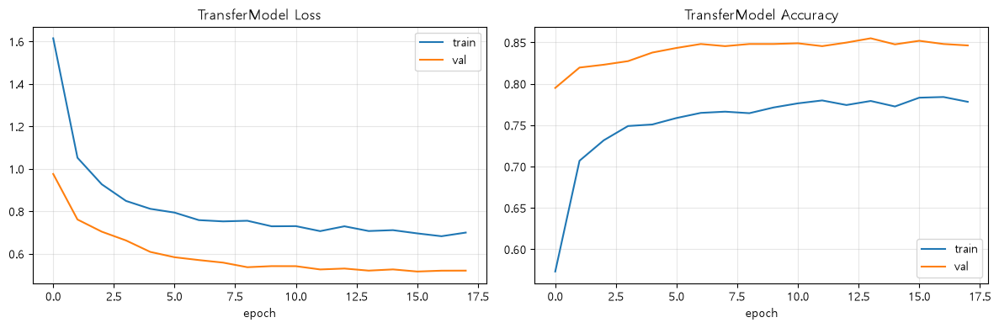

In [18]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(transfer_history['loss'], label='train')
plt.plot(transfer_history['val_loss'], label='val')
plt.title('TransferModel Loss')
plt.xlabel('epoch')
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(transfer_history['accuracy'], label='train')
plt.plot(transfer_history['val_accuracy'], label='val')
plt.title('TransferModel Accuracy')
plt.xlabel('epoch')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 3-1. 학습률(lr) 튜닝 — unfreeze 모델 (val 기준)

지금까지 unfreeze의 lr=1e-4는 freeze 때(5e-4)보다 낮춰야 한다는 일반적인 감으로 고른 값이었고, 실제로 비교해본 적은 없었다. 여기서 후보 lr 몇 가지를 **짧게(4 epoch, patience 2, 스케줄러 없이)** 학습해 val_macro_f1로 비교한다 — 스케줄러를 끄는 이유는 스케줄러가 후보마다 다른 시점에 lr을 낮춰버리면 "어떤 시작 lr이 더 좋은가"라는 비교 자체가 흐려지기 때문이다. 승자로 뽑힌 lr에 스케줄러(ReduceLROnPlateau)를 얹어 최종 학습을 진행한다.

In [19]:
LR_CANDIDATES = [5e-5, 1e-4, 3e-4]
EPOCHS_LR_SWEEP = 4

lr_sweep_results = {}
for lr in LR_CANDIDATES:
    model = TransferModel(num_classes=len(class_names), freeze=False)
    history = train_model(model, train_loader, val_loader,
                          epochs=EPOCHS_LR_SWEEP, lr=lr, patience=2,
                          class_weights=class_weights if use_class_weight_final else None,
                          ckpt_path=f'lr_sweep_{lr:.0e}.pt', label=f'unfreeze lr={lr:.0e}')
    lr_sweep_results[lr] = max(history['val_macro_f1'])

print(f'\n{"lr":>10s}{"val_macro_f1(best epoch)":>28s}')
for lr, f1 in lr_sweep_results.items():
    print(f'{lr:10.0e}{f1:28.4f}')

best_lr = max(lr_sweep_results, key=lr_sweep_results.get)
print(f'\n최고 val_macro_f1 lr: {best_lr:.0e}')

[unfreeze lr=5e-05] Epoch 1/4:   0%|          | 0/170 [00:00<?, ?it/s]

[unfreeze lr=5e-05] Epoch 1/4 (52.8s) train_loss=1.3652 train_acc=0.6295 val_loss=0.3452 val_acc=0.9146 val_macro_f1=0.8815 val_macro_recall=0.8899


[unfreeze lr=5e-05] Epoch 2/4:   0%|          | 0/170 [00:00<?, ?it/s]

[unfreeze lr=5e-05] Epoch 2/4 (53.0s) train_loss=0.3295 train_acc=0.9056 val_loss=0.1823 val_acc=0.9461 val_macro_f1=0.9254 val_macro_recall=0.9283


[unfreeze lr=5e-05] Epoch 3/4:   0%|          | 0/170 [00:00<?, ?it/s]

[unfreeze lr=5e-05] Epoch 3/4 (52.8s) train_loss=0.1990 train_acc=0.9432 val_loss=0.1341 val_acc=0.9625 val_macro_f1=0.9497 val_macro_recall=0.9517


... (14 outputs left out)

[unfreeze lr=3e-04] Epoch 3/4:   0%|          | 0/170 [00:00<?, ?it/s]

[unfreeze lr=3e-04] Epoch 3/4 (52.9s) train_loss=0.1396 train_acc=0.9572 val_loss=0.1645 val_acc=0.9547 val_macro_f1=0.9367 val_macro_recall=0.9371


[unfreeze lr=3e-04] Epoch 4/4:   0%|          | 0/170 [00:00<?, ?it/s]

[unfreeze lr=3e-04] Epoch 4/4 (52.7s) train_loss=0.1102 train_acc=0.9651 val_loss=0.1613 val_acc=0.9521 val_macro_f1=0.9319 val_macro_recall=0.9348

        lr    val_macro_f1(best epoch)
     5e-05                      0.9501
     1e-04                      0.9529
     3e-04                      0.9367

최고 val_macro_f1 lr: 1e-04


In [20]:
# 전이학습(unfreeze): 백본까지 같이 학습 — freeze와 비교하기 위한 두 번째 전이학습 변형
# 학습률은 위 3-1 튜닝에서 고른 best_lr을 사용한다
# 학습률 스케줄러(ReduceLROnPlateau) 추가: val_loss가 1epoch 동안 개선 안 되면 lr을 0.1배로 낮춰서
# 조기 종료(patience=3)가 발동하기 전에 더 낮은 lr로 추가 개선 여지를 준다
EPOCHS_TRANSFER_UNFREEZE = 15  # 조기 종료가 있으므로 상한을 넉넉히 잡는다

transfer_unfreeze_model = TransferModel(num_classes=len(class_names), freeze=False)
transfer_unfreeze_history = train_model(transfer_unfreeze_model, train_loader, val_loader,
                                        epochs=EPOCHS_TRANSFER_UNFREEZE, lr=best_lr, patience=3,
                                        use_scheduler=True, scheduler_patience=1,
                                        class_weights=class_weights if use_class_weight_final else None,
                                        ckpt_path='best_transfer_unfreeze_model.pt',
                                        label='EfficientNetV2S(unfreeze)')

[EfficientNetV2S(unfreeze)] Epoch 1/15:   0%|          | 0/170 [00:00<?, ?it/s]

[EfficientNetV2S(unfreeze)] Epoch 1/15 (52.5s) train_loss=0.8926 train_acc=0.7550 val_loss=0.1845 val_acc=0.9513 val_macro_f1=0.9312 val_macro_recall=0.9342 lr=1.0e-04


[EfficientNetV2S(unfreeze)] Epoch 2/15:   0%|          | 0/170 [00:00<?, ?it/s]

[EfficientNetV2S(unfreeze)] Epoch 2/15 (53.6s) train_loss=0.2036 train_acc=0.9409 val_loss=0.1531 val_acc=0.9586 val_macro_f1=0.9437 val_macro_recall=0.9450 lr=1.0e-04


[EfficientNetV2S(unfreeze)] Epoch 3/15:   0%|          | 0/170 [00:00<?, ?it/s]

[EfficientNetV2S(unfreeze)] Epoch 3/15 (53.9s) train_loss=0.1258 train_acc=0.9654 val_loss=0.1244 val_acc=0.9642 val_macro_f1=0.9510 val_macro_recall=0.9543 lr=1.0e-04


... (18 outputs left out)

[EfficientNetV2S(unfreeze)] Epoch 13/15:   0%|          | 0/170 [00:00<?, ?it/s]

[EfficientNetV2S(unfreeze)] Epoch 13/15 (52.9s) train_loss=0.0266 train_acc=0.9930 val_loss=0.1062 val_acc=0.9720 val_macro_f1=0.9611 val_macro_recall=0.9608 lr=1.0e-05


[EfficientNetV2S(unfreeze)] Epoch 14/15:   0%|          | 0/170 [00:00<?, ?it/s]

[EfficientNetV2S(unfreeze)] Epoch 14/15 (52.6s) train_loss=0.0217 train_acc=0.9946 val_loss=0.1067 val_acc=0.9720 val_macro_f1=0.9613 val_macro_recall=0.9608 lr=1.0e-06
[EfficientNetV2S(unfreeze)] val_macro_f1이 3 epoch 동안 개선되지 않아 14/15 epoch에서 조기 종료


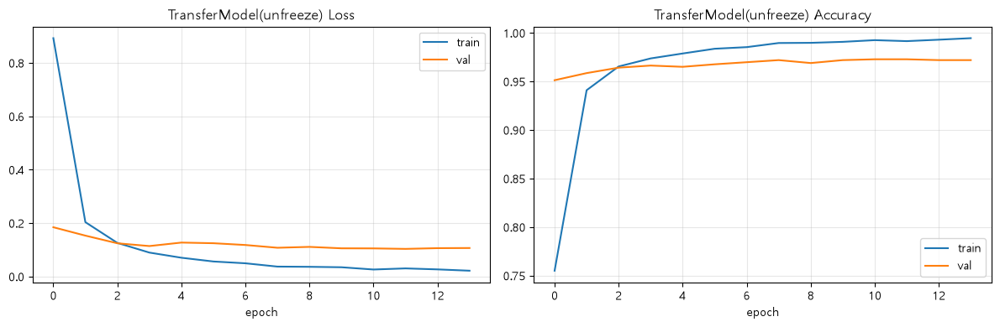

In [21]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(transfer_unfreeze_history['loss'], label='train')
plt.plot(transfer_unfreeze_history['val_loss'], label='val')
plt.title('TransferModel(unfreeze) Loss')
plt.xlabel('epoch')
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(transfer_unfreeze_history['accuracy'], label='train')
plt.plot(transfer_unfreeze_history['val_accuracy'], label='val')
plt.title('TransferModel(unfreeze) Accuracy')
plt.xlabel('epoch')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 4. 검증 성능 비교 및 최종 모델 선정

비교는 val 지표로만 수행한다(`test_loader`는 다음 절 최종 평가에서 1회만 사용).

In [22]:
# 조기 종료를 쓰면 마지막 epoch이 최고 성능이 아닐 수 있으므로,
# history의 마지막 값이 아니라 저장된 best 체크포인트를 다시 불러와 val_loader로 평가한다
candidate_specs = [
    ("BaselineCNN", "best_baseline_cnn.pt",
     lambda: BaselineCNN(num_classes=len(class_names))),
    ("EfficientNetV2S(freeze)", "best_transfer_model.pt",
     lambda: TransferModel(num_classes=len(class_names), freeze=True)),
    ("EfficientNetV2S(unfreeze)", "best_transfer_unfreeze_model.pt",
     lambda: TransferModel(num_classes=len(class_names), freeze=False)),
]

criterion = nn.CrossEntropyLoss(weight=class_weights if use_class_weight_final else None)

print(f'{"모델":25s}{"val_loss":>10s}{"val_acc":>10s}{"val_macro_f1":>14s}{"val_macro_recall":>18s}')
candidates = []
for name, ckpt, builder in candidate_specs:
    model = builder()
    model.load_state_dict(torch.load(ckpt, map_location=device))
    model = model.to(device)
    m = evaluate(model, val_loader, criterion)
    print(f'{name:25s}{m["loss"]:10.4f}{m["accuracy"]:10.4f}'
          f'{m["macro_f1"]:14.4f}{m["macro_recall"]:18.4f}')
    candidates.append((name, m, ckpt, model))

best_name, best_val_metrics, best_ckpt, best_model = max(candidates, key=lambda x: x[1]['macro_f1'])
print(f'\n검증 macro F1 기준 최종 선정 모델: {best_name}')

모델                         val_loss   val_acc  val_macro_f1  val_macro_recall


BaselineCNN                  0.8344    0.7360        0.7095            0.7307


EfficientNetV2S(freeze)      0.5210    0.8550        0.8009            0.8128


EfficientNetV2S(unfreeze)    0.1053    0.9728        0.9629            0.9619

검증 macro F1 기준 최종 선정 모델: EfficientNetV2S(unfreeze)


## 5. 최종 모델 평가 (test)

test는 여기서 1회만 사용한다.

In [23]:
test_metrics = evaluate(best_model, test_loader)
print(f'[TEST / {best_name}] accuracy={test_metrics["accuracy"]:.4f} '
      f'macro_f1={test_metrics["macro_f1"]:.4f} macro_recall={test_metrics["macro_recall"]:.4f}')
print()
print(classification_report(test_metrics['trues'], test_metrics['preds'],
                            target_names=class_names, zero_division=0))

[TEST / EfficientNetV2S(unfreeze)] accuracy=0.9743 macro_f1=0.9682 macro_recall=0.9688

              precision    recall  f1-score   support

     battery       0.99      0.98      0.98       143
  biological       0.98      0.99      0.98       149
 brown-glass       0.97      0.98      0.97        92
   cardboard       0.98      0.94      0.96       135
     clothes       1.00      0.98      0.99       800
 green-glass       1.00      1.00      1.00        93
       metal       0.92      0.95      0.93       116
       paper       0.96      0.99      0.97       158
     plastic       0.92      0.93      0.92       130
       shoes       0.95      0.99      0.97       298
       trash       1.00      0.96      0.98       106
 white-glass       0.96      0.94      0.95       117

    accuracy                           0.97      2337
   macro avg       0.97      0.97      0.97      2337
weighted avg       0.97      0.97      0.97      2337



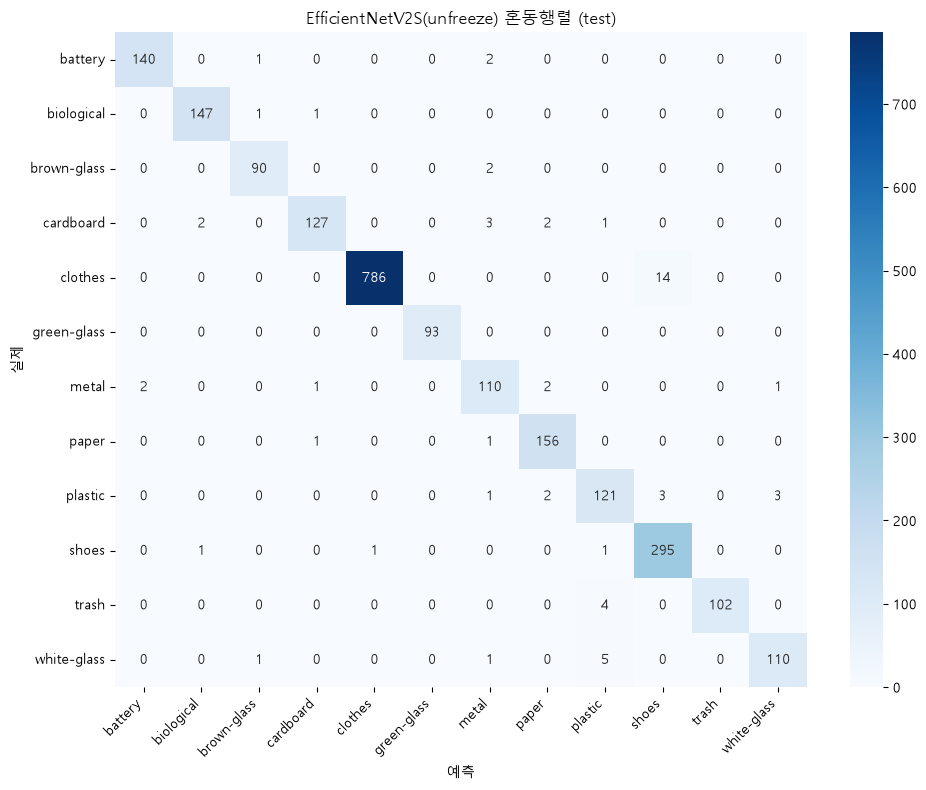

가장 많이 헷갈린 클래스 쌍 (실제 -> 예측) Top 5
clothes      -> shoes       : 14건
white-glass  -> plastic     : 5건
trash        -> plastic     : 4건
plastic      -> white-glass : 3건
plastic      -> shoes       : 3건


In [24]:
import seaborn as sns

cm = confusion_matrix(test_metrics['trues'], test_metrics['preds'])
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
           xticklabels=class_names, yticklabels=class_names)
plt.xlabel('예측')
plt.ylabel('실제')
plt.title(f'{best_name} 혼동행렬 (test)')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# 대각선을 제외하고 가장 많이 헷갈린 클래스 쌍 확인
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)
pairs = []
for i in range(len(class_names)):
    for j in range(len(class_names)):
        if cm_off[i, j] > 0:
            pairs.append((cm_off[i, j], class_names[i], class_names[j]))
pairs.sort(reverse=True)

print('가장 많이 헷갈린 클래스 쌍 (실제 -> 예측) Top 5')
for cnt, real, pred in pairs[:5]:
    print(f'{real:12s} -> {pred:12s}: {cnt}건')

### 5-1. 확신 있게 틀린 예측 전수 확인 (라벨 노이즈 점검)

모델이 아주 높은 확률로 틀린 예측은 두 가지 경우로 나뉜다: (1) 정말 헷갈리는 사진(진짜 모델의 한계) (2) 원본 라벨 자체가 잘못됐을 가능성. **held-out(val+test) 전체**에서 확신도(softmax 확률) 0.9 이상인데 틀린 사례를 **전부** 직접 눈으로 확인해 어느 쪽에 가까운지 점검한다(train은 모델이 암기했을 수 있어 이 진단법으로는 라벨 오류를 못 잡으므로 제외). 이 노트북에서 라벨 오류 자체를 고치지는 않고, 있는 그대로 관찰·기록만 한다.

In [25]:
# [NEW] 01~07.ipynb에 없는 기법: softmax 확률 기반 '확신 있게 틀린 예측' 전수 진단 —
# val+test(held-out) 전체에서 예측이 틀렸으면서 확신도가 높은 사례를 모두 찾는다.
@torch.no_grad()
def get_probs(model, loader):
    model.eval()
    probs_all = []
    for xb, yb in loader:
        xb = xb.to(device)
        probs = F.softmax(model(xb), dim=1)
        probs_all.append(probs.cpu().numpy())
    return np.concatenate(probs_all)

val_probs = get_probs(best_model, val_loader)
test_probs = get_probs(best_model, test_loader)

holdout_idx = val_idx + test_idx
holdout_split = ['val'] * len(val_idx) + ['test'] * len(test_idx)
holdout_trues = np.array([targets[i] for i in holdout_idx])
holdout_probs = np.concatenate([val_probs, test_probs])
holdout_preds = holdout_probs.argmax(axis=1)
holdout_conf = holdout_probs.max(axis=1)

CONF_THRESHOLD = 0.9
wrong_mask = holdout_preds != holdout_trues
suspect_mask = wrong_mask & (holdout_conf >= CONF_THRESHOLD)
suspect_pos = np.where(suspect_mask)[0]
order = suspect_pos[np.argsort(-holdout_conf[suspect_pos])]

print(f'held-out(val+test) 전체 {len(holdout_idx)}장 중 오분류 {wrong_mask.sum()}건, '
      f'그 중 확신도 >= {CONF_THRESHOLD} : {len(order)}건 (라벨 오류 의심 사례)')
print(f'\n{"#":>3s} {"split":5s} {"실제":12s} {"예측":12s} {"확신도":>6s}  파일명')
for rank, pos in enumerate(order, 1):
    gi = holdout_idx[pos]
    fname = os.path.basename(label_only.samples[gi][0])
    print(f'{rank:3d} {holdout_split[pos]:5s} {class_names[holdout_trues[pos]]:12s} '
          f'{class_names[holdout_preds[pos]]:12s} {holdout_conf[pos]:6.3f}  {fname}')

held-out(val+test) 전체 4655장 중 오분류 123건, 그 중 확신도 >= 0.9 : 59건 (라벨 오류 의심 사례)

  # split 실제           예측              확신도  파일명
  1 val   plastic      green-glass   0.999  plastic353.jpg
  2 test  shoes        clothes       0.999  shoes1826.jpg
  3 test  clothes      shoes         0.998  clothes3062.jpg
  4 val   trash        clothes       0.998  trash427.jpg
  5 val   clothes      shoes         0.997  clothes3330.jpg
  6 test  plastic      white-glass   0.997  plastic834.jpg
  7 test  clothes      shoes         0.997  clothes5002.jpg
  8 test  clothes      shoes         0.997  clothes2197.jpg
  9 test  brown-glass  metal         0.996  brown-glass245.jpg
 10 test  battery      brown-glass   0.996  battery872.jpg
 11 test  clothes      shoes         0.996  clothes4465.jpg
 12 val   white-glass  green-glass   0.995  white-glass58.jpg
 13 val   plastic      paper         0.995  plastic345.jpg
 14 test  clothes      shoes         0.995  clothes1229.jpg
 15 test  clothes      shoes         0.9

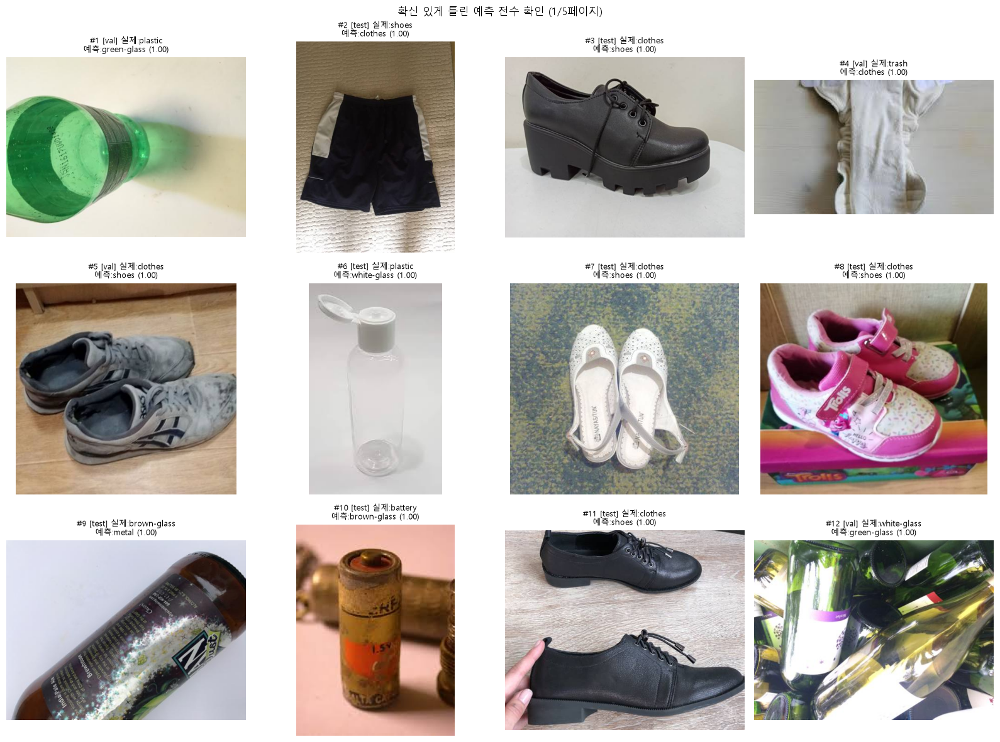

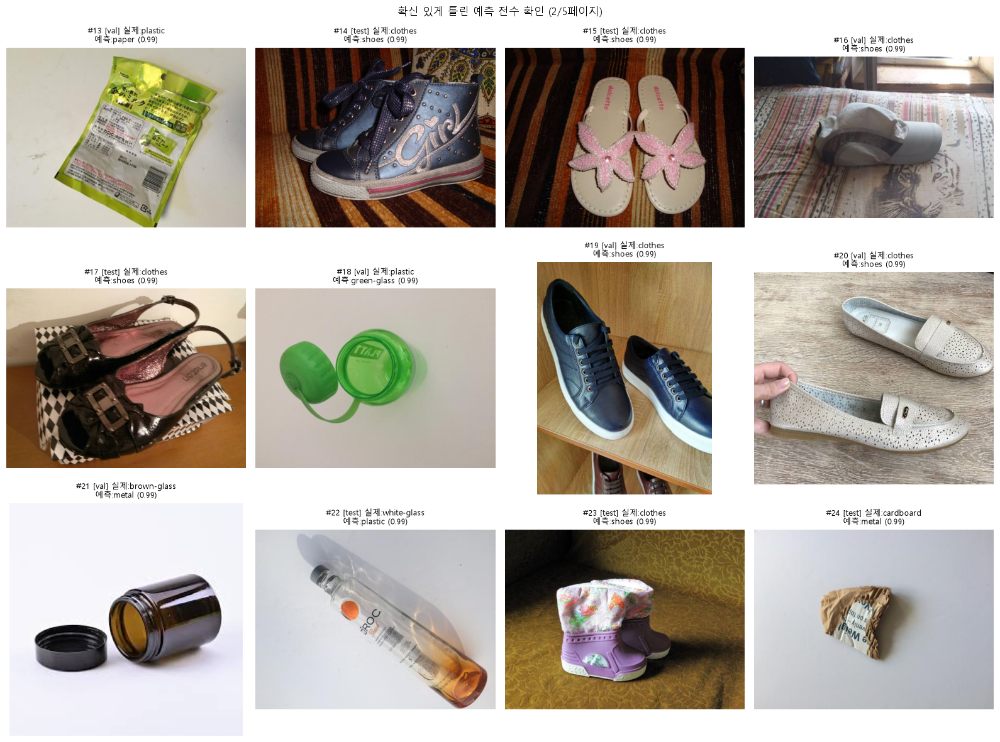

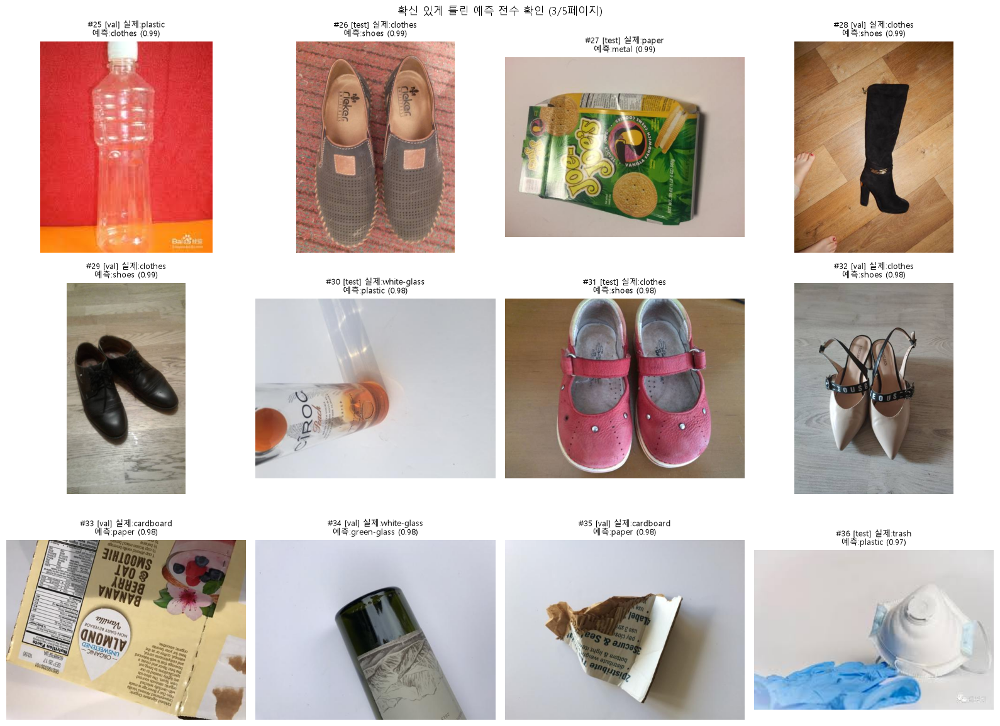

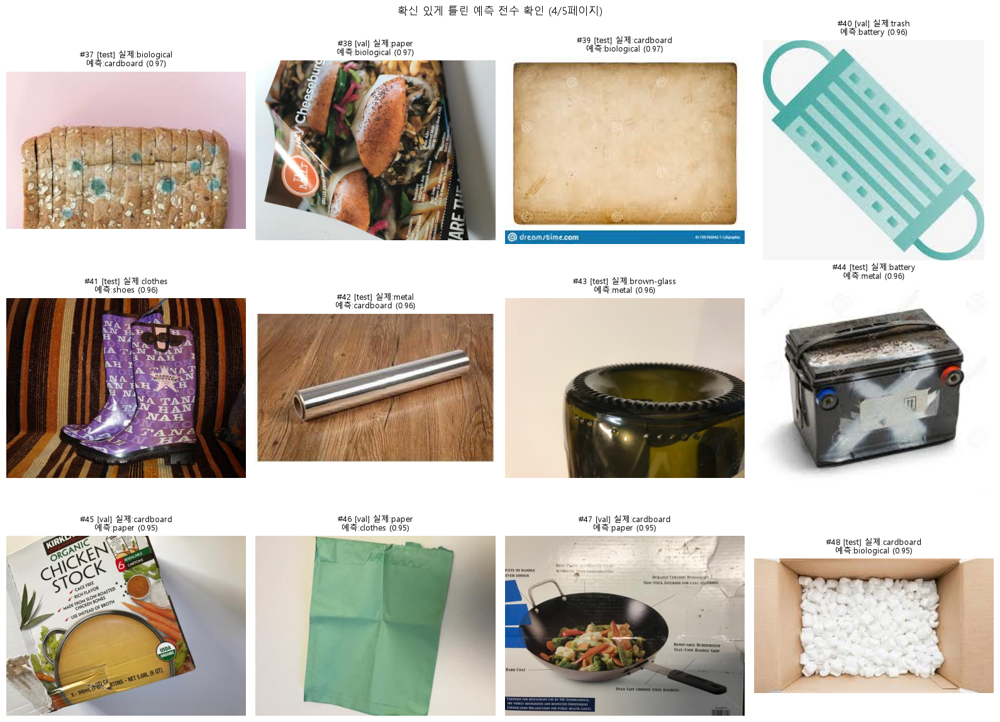

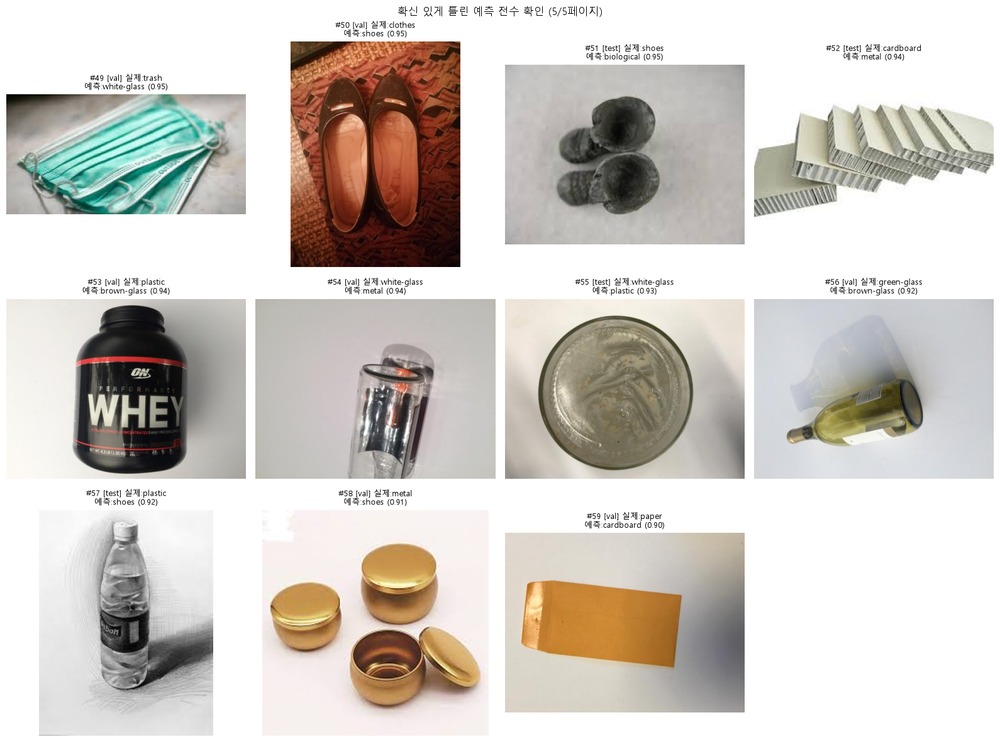

In [26]:
# 위 후보 전체를 이미지로 확인 (한 페이지에 12개씩)
PER_PAGE = 12
n_pages = (len(order) + PER_PAGE - 1) // PER_PAGE
for p in range(n_pages):
    chunk = order[p * PER_PAGE:(p + 1) * PER_PAGE]
    rows = (len(chunk) + 3) // 4
    plt.figure(figsize=(16, 4 * rows))
    for k, pos in enumerate(chunk):
        gi = holdout_idx[pos]
        path, _ = label_only.samples[gi]
        rank = p * PER_PAGE + k + 1
        plt.subplot(rows, 4, k + 1)
        plt.imshow(Image.open(path))
        plt.title(f'#{rank} [{holdout_split[pos]}] 실제:{class_names[holdout_trues[pos]]}\n'
                  f'예측:{class_names[holdout_preds[pos]]} ({holdout_conf[pos]:.2f})', fontsize=9)
        plt.axis('off')
    plt.suptitle(f'확신 있게 틀린 예측 전수 확인 ({p + 1}/{n_pages}페이지)')
    plt.tight_layout()
    plt.show()

**5-1 결과 요약 (직접 확인)**

held-out(val+test) 4,655장 중 확신도 0.9 이상으로 틀린 59건을 전부 열어봤다.

- **`clothes ↔ shoes` 20건(59건의 34%)**: 그중 19건이 신발 사진(운동화·샌들·부츠·로퍼·구두)이 `clothes` 폴더에 들어가 있는 **명백한 라벨 오류**였다. 반대 방향(shoes 폴더에 반바지 사진)이 1건.
- **유리 색상 클래스 혼동 4건 안팎**: `white-glass`/`green-glass`/`brown-glass` 사이에서 사진상 병 색깔이 라벨과 다르게 보이는 경우(예: `white-glass`로 라벨된 병이 실제로는 짙은 녹색) — 색상 서브클래스 라벨이 부정확할 가능성이 있으나 조명 때문일 수도 있어 100% 확신하기는 어렵다.
- **사진이 아닌 이미지 2건**: 마스크 일러스트(클립아트), 볼펜 스케치 그림 — 실제 촬영 사진이 아닌 이미지가 데이터셋에 섞여 있다.
- **나머지 약 33건**: `cardboard↔paper`, `metal↔brown-glass`, `biological↔cardboard` 등 — 라벨은 맞지만 재질·색상·구도가 실제로 헷갈리는 진짜 어려운 사례이거나, `cardboard`/`paper`처럼 카테고리 경계 자체가 원래 모호한 경우로 판단된다.

**결론**: 실험 내내 반복됐던 `clothes → shoes` 오분류의 상당수(held-out 기준 20건 중 19건)는 **모델의 한계가 아니라 원본 데이터셋의 라벨 오류**였다. 이 노트북에서 라벨을 직접 고치지는 않았다 — 전수 재검수·정정은 범위 밖으로 판단하고, 발견 사실만 기록한다.

### 5-2. train 데이터 라벨 오류 점검 (2-fold out-of-fold 진단)

5-1의 진단은 val+test(held-out)만 대상으로 했다 — train은 모델이 그 라벨을 그대로 암기했을 수 있어서, 라벨이 틀렸어도 모델이 '확신 있게' 그 틀린 라벨을 재현해버려 이 방법으로는 못 잡는다.

train 전체를 정직하게 진단하려면 "train을 안 본 상태의 모델"이 필요하다. 그래서 **train을 절반씩(fold A/B) 나눠 서로 반대쪽으로 학습한 두 모델을 교차 평가**한다 — fold A로 학습한 모델로 fold B를(모델이 안 본 데이터), fold B로 학습한 모델로 fold A를 평가하면 train 10,838장 전체에 대해 '안 본 상태'의 정직한 예측을 얻을 수 있다(= out-of-fold, OOF). 근접 중복 덩어리(cluster)는 원래 분할과 마찬가지로 같은 fold에만 들어가도록 유지한다.

In [27]:
# [NEW] 01~07.ipynb에 없는 기법: 2-fold out-of-fold(OOF) 교차 평가 —
# train 라벨 오류는 모델이 암기해버려 5-1 방식(확신 있게 틀림)으로 못 잡으므로,
# train을 절반씩 나눠 서로 반대쪽 fold로 학습한 모델로 교차 평가해 '안 본 상태'의 정직한 예측을 만든다.
train_idx_set = set(train_idx)
train_clusters = [c for c in clusters if c[0] in train_idx_set]  # 원래 분할에서 train으로 통째로 배정된 덩어리

fold_a_idx, fold_b_idx = [], []
rng2 = np.random.RandomState(123)  # 원래 분할과 다른 시드
for c in range(len(class_names)):
    c_clusters = [cluster for cluster in train_clusters if targets[cluster[0]] == c]
    rng2.shuffle(c_clusters)
    n = sum(len(cluster) for cluster in c_clusters)
    n_a = n // 2
    cum = 0
    for cluster in c_clusters:
        if cum < n_a:
            fold_a_idx += cluster
        else:
            fold_b_idx += cluster
        cum += len(cluster)

print(f'fold A {len(fold_a_idx)} / fold B {len(fold_b_idx)} '
      f'(합계 {len(fold_a_idx) + len(fold_b_idx)}, 원래 train {len(train_idx)})')

fold A 5415 / fold B 5423 (합계 10838, 원래 train 10838)


In [28]:
def make_fold_loader(idx_list, tf, use_sampler):
    ds = datasets.ImageFolder(data_dir, transform=tf)
    subset = Subset(ds, idx_list)
    if use_sampler:
        weights = class_weight_np[targets[idx_list]]
        sampler = WeightedRandomSampler(weights=weights, num_samples=len(weights), replacement=True)
        loader = DataLoader(subset, batch_size=BATCH_SIZE, sampler=sampler)
    else:
        loader = DataLoader(subset, batch_size=BATCH_SIZE, shuffle=True)
    return loader

# 최종 채택 설정(비율유지 크롭 + WeightedRandomSampler)과 최적 lr을 그대로 재사용
fold_a_loader = make_fold_loader(fold_a_idx, train_tf, use_sampler_final)
fold_b_loader = make_fold_loader(fold_b_idx, train_tf, use_sampler_final)

EPOCHS_FOLD = 15

model_a = TransferModel(num_classes=len(class_names), freeze=False)
history_fold_a = train_model(model_a, fold_a_loader, val_loader,
                             epochs=EPOCHS_FOLD, lr=best_lr, patience=3,
                             use_scheduler=True, scheduler_patience=1,
                             class_weights=class_weights if use_class_weight_final else None,
                             ckpt_path='fold_a_model.pt', label='OOF-foldA')

model_b = TransferModel(num_classes=len(class_names), freeze=False)
history_fold_b = train_model(model_b, fold_b_loader, val_loader,
                             epochs=EPOCHS_FOLD, lr=best_lr, patience=3,
                             use_scheduler=True, scheduler_patience=1,
                             class_weights=class_weights if use_class_weight_final else None,
                             ckpt_path='fold_b_model.pt', label='OOF-foldB')

[OOF-foldA] Epoch 1/15:   0%|          | 0/85 [00:00<?, ?it/s]

[OOF-foldA] Epoch 1/15 (28.9s) train_loss=1.4067 train_acc=0.6146 val_loss=0.3700 val_acc=0.9038 val_macro_f1=0.8635 val_macro_recall=0.8693 lr=1.0e-04


[OOF-foldA] Epoch 2/15:   0%|          | 0/85 [00:00<?, ?it/s]

[OOF-foldA] Epoch 2/15 (29.1s) train_loss=0.3324 train_acc=0.9042 val_loss=0.2431 val_acc=0.9314 val_macro_f1=0.9104 val_macro_recall=0.9132 lr=1.0e-04


[OOF-foldA] Epoch 3/15:   0%|          | 0/85 [00:00<?, ?it/s]

[OOF-foldA] Epoch 3/15 (29.2s) train_loss=0.1935 train_acc=0.9452 val_loss=0.1843 val_acc=0.9513 val_macro_f1=0.9351 val_macro_recall=0.9378 lr=1.0e-04


... (36 outputs left out)

[OOF-foldB] Epoch 14/15:   0%|          | 0/85 [00:00<?, ?it/s]

[OOF-foldB] Epoch 14/15 (29.2s) train_loss=0.0320 train_acc=0.9910 val_loss=0.1637 val_acc=0.9564 val_macro_f1=0.9397 val_macro_recall=0.9392 lr=1.0e-07


[OOF-foldB] Epoch 15/15:   0%|          | 0/85 [00:00<?, ?it/s]

[OOF-foldB] Epoch 15/15 (29.0s) train_loss=0.0322 train_acc=0.9911 val_loss=0.1671 val_acc=0.9569 val_macro_f1=0.9397 val_macro_recall=0.9394 lr=1.0e-07


In [29]:
# fold A 모델은 fold B를, fold B 모델은 fold A를 평가 -> train 전체에 대한 out-of-fold 예측
model_a.load_state_dict(torch.load('fold_a_model.pt', map_location=device))
model_b.load_state_dict(torch.load('fold_b_model.pt', map_location=device))
model_a, model_b = model_a.to(device).eval(), model_b.to(device).eval()

def get_probs_for_idx(model, idx_list, tf):
    ds = datasets.ImageFolder(data_dir, transform=tf)
    loader = DataLoader(Subset(ds, idx_list), batch_size=BATCH_SIZE, shuffle=False)
    return get_probs(model, loader)

probs_b_from_a = get_probs_for_idx(model_a, fold_b_idx, eval_tf)
probs_a_from_b = get_probs_for_idx(model_b, fold_a_idx, eval_tf)

oof_idx = fold_b_idx + fold_a_idx
oof_probs = np.concatenate([probs_b_from_a, probs_a_from_b])
oof_trues = np.array([targets[i] for i in oof_idx])
oof_preds = oof_probs.argmax(axis=1)
oof_conf = oof_probs.max(axis=1)

CONF_THRESHOLD = 0.9
wrong_mask = oof_preds != oof_trues
suspect_mask = wrong_mask & (oof_conf >= CONF_THRESHOLD)
suspect_pos = np.where(suspect_mask)[0]
order = suspect_pos[np.argsort(-oof_conf[suspect_pos])]

print(f'train(OOF) 전체 {len(oof_idx)}장 중 오분류 {wrong_mask.sum()}건, '
      f'그 중 확신도 >= {CONF_THRESHOLD} : {len(order)}건 (라벨 오류 의심 사례)')
print(f'\n{"#":>3s} {"실제":12s} {"예측":12s} {"확신도":>6s}  파일명')
for rank, pos in enumerate(order, 1):
    gi = oof_idx[pos]
    fname = os.path.basename(label_only.samples[gi][0])
    print(f'{rank:3d} {class_names[oof_trues[pos]]:12s} '
          f'{class_names[oof_preds[pos]]:12s} {oof_conf[pos]:6.3f}  {fname}')

train(OOF) 전체 10838장 중 오분류 382건, 그 중 확신도 >= 0.9 : 145건 (라벨 오류 의심 사례)

  # 실제           예측              확신도  파일명
  1 cardboard    paper         0.999  cardboard122.jpg
  2 clothes      shoes         0.999  clothes2185.jpg
  3 plastic      white-glass   0.999  plastic836.jpg
  4 clothes      paper         0.999  clothes1953.jpg
  5 metal        battery       0.998  metal475.jpg
  6 clothes      shoes         0.998  clothes4319.jpg
  7 plastic      metal         0.998  plastic249.jpg
  8 white-glass  metal         0.998  white-glass198.jpg
  9 clothes      shoes         0.998  clothes4611.jpg
 10 plastic      paper         0.998  plastic199.jpg
 11 paper        metal         0.998  paper906.jpg
 12 battery      metal         0.998  battery808.jpg
 13 cardboard    paper         0.998  cardboard529.jpg
 14 green-glass  brown-glass   0.998  green-glass558.jpg
 15 plastic      white-glass   0.998  plastic442.jpg
 16 clothes      shoes         0.998  clothes5201.jpg
 17 paper        biological

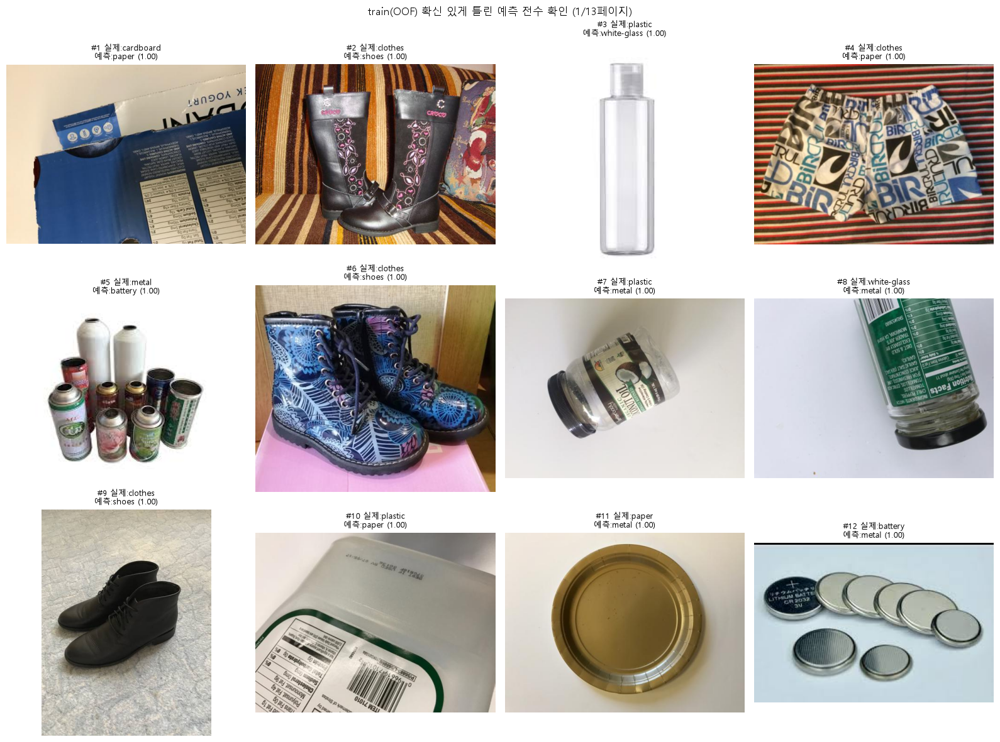

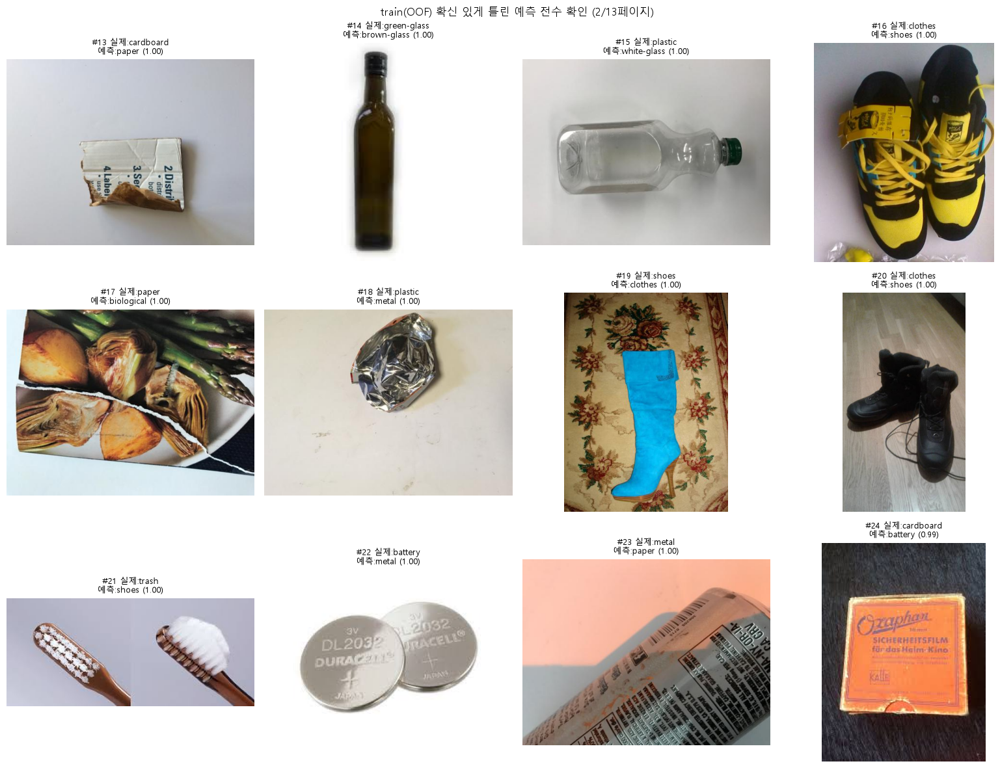

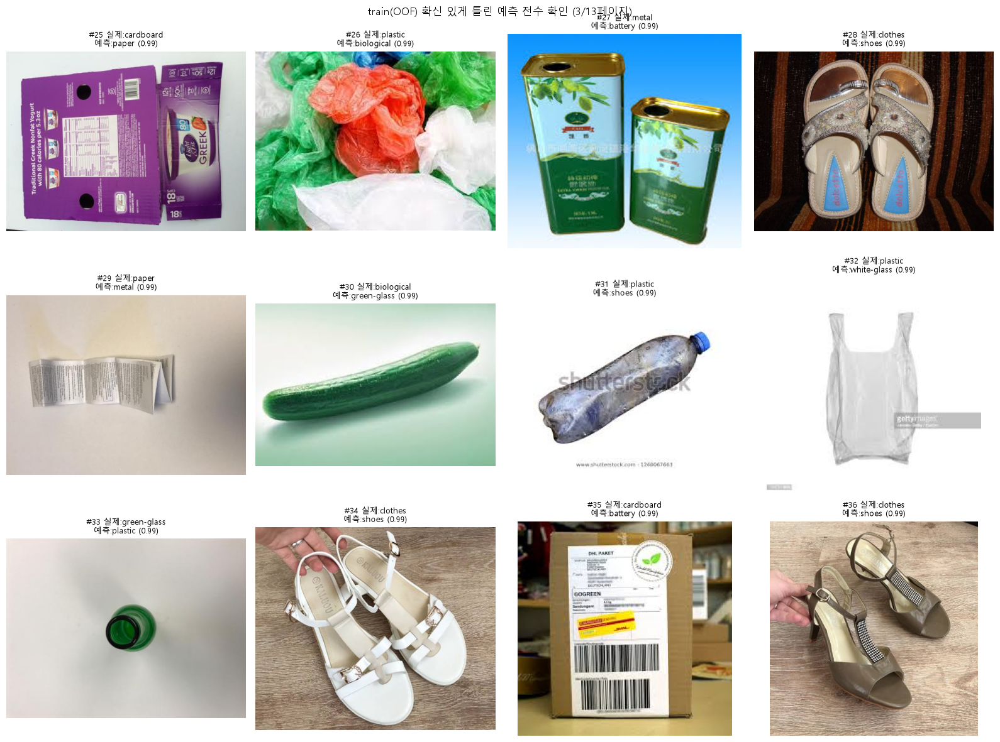

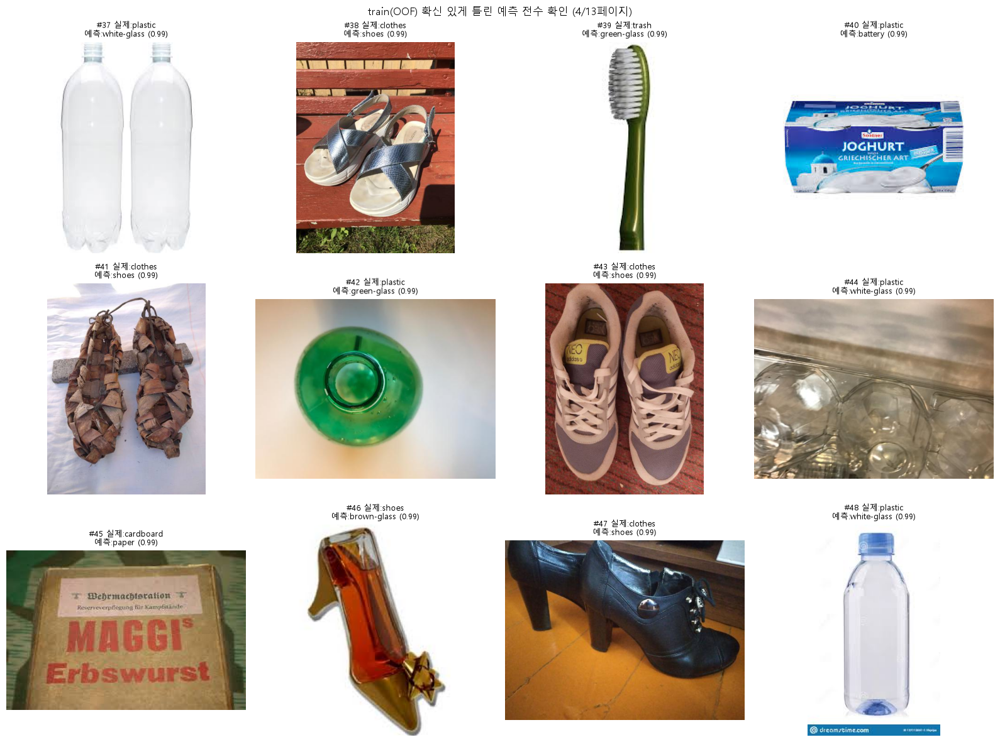

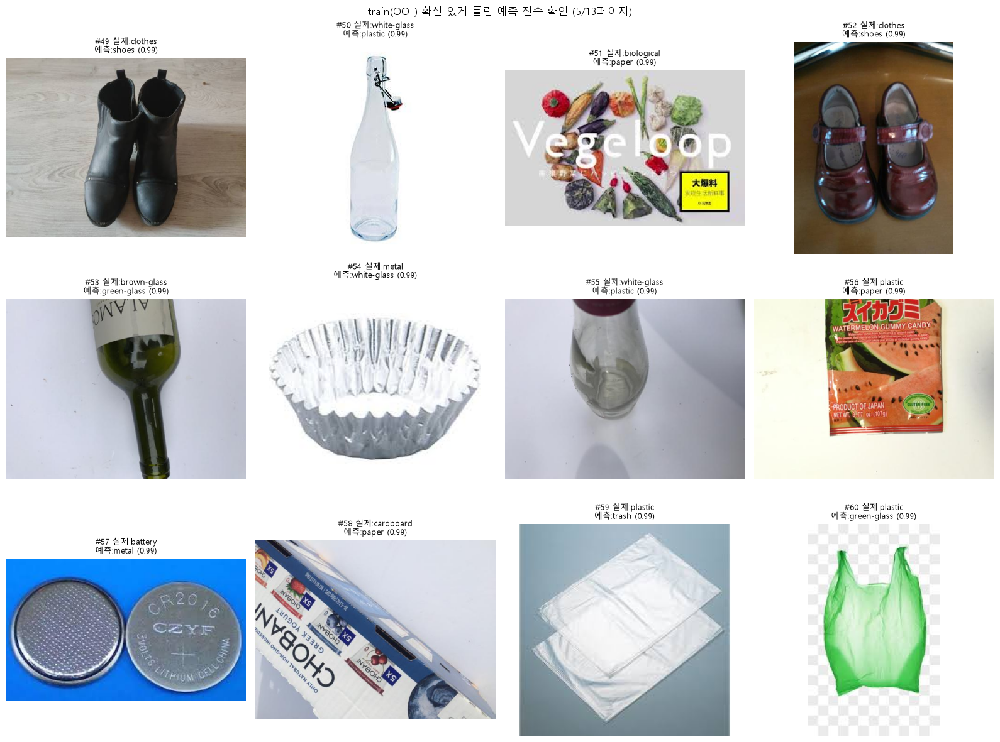

...

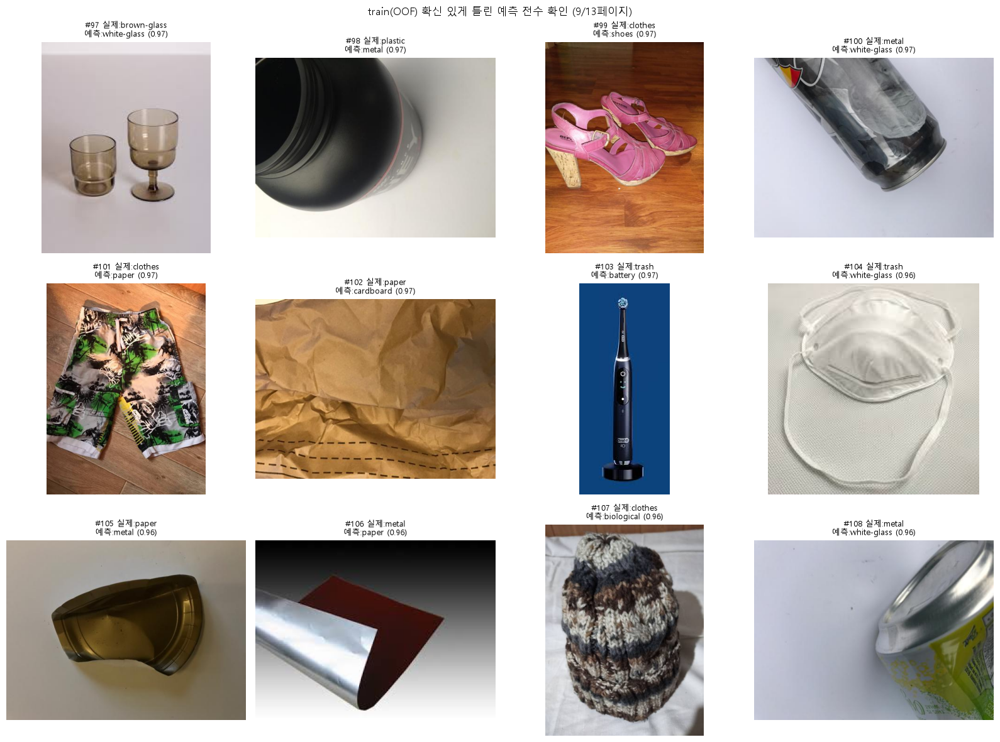

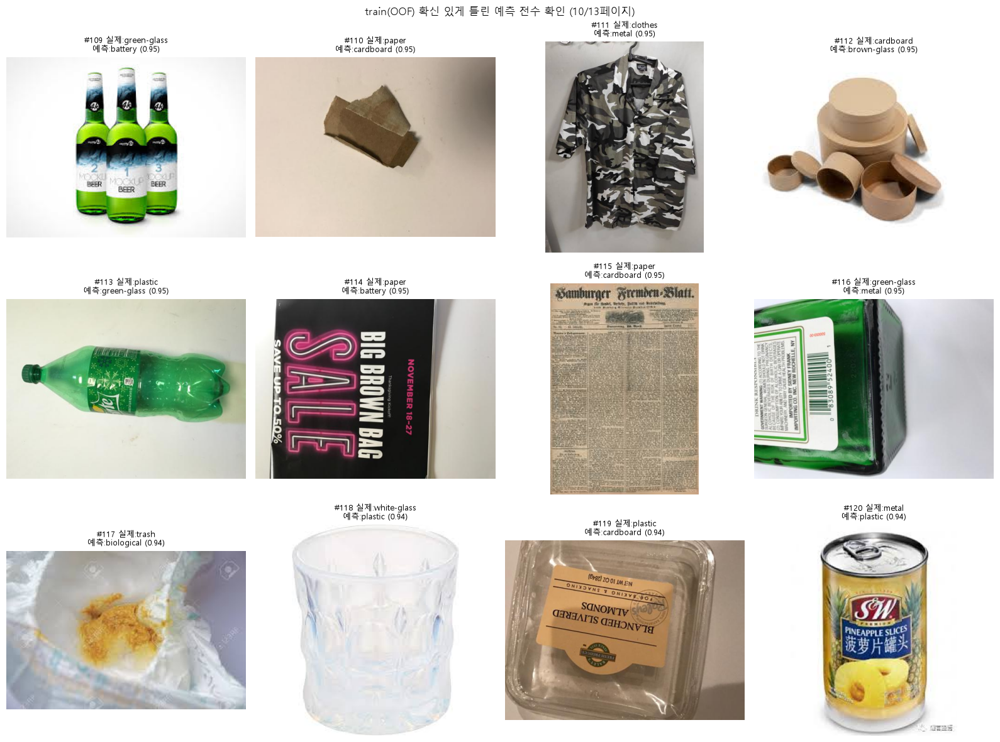

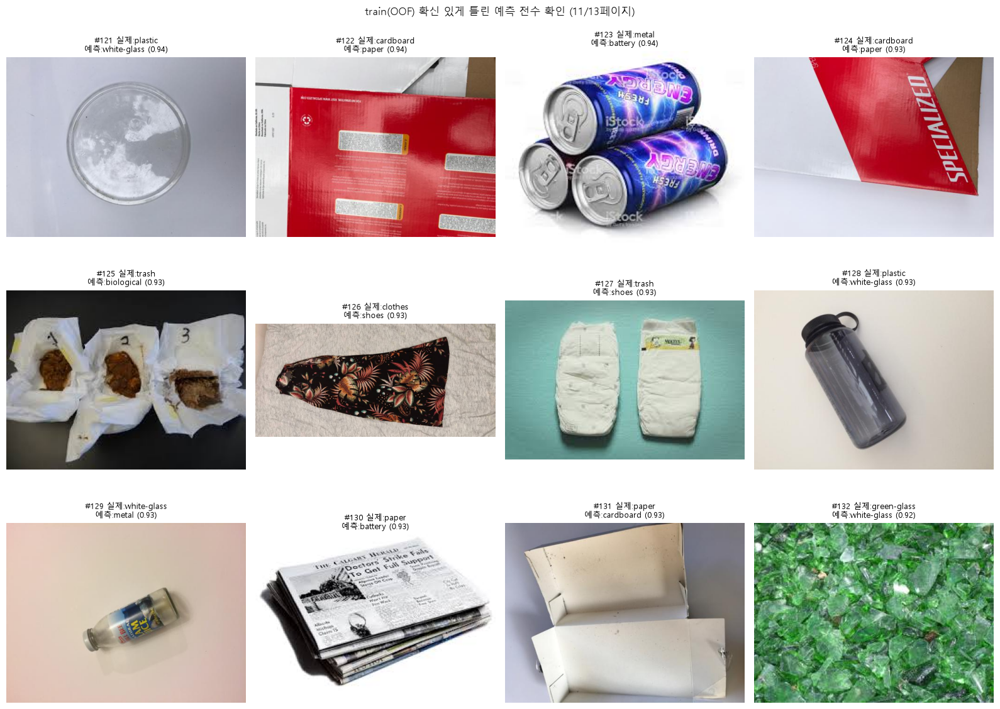

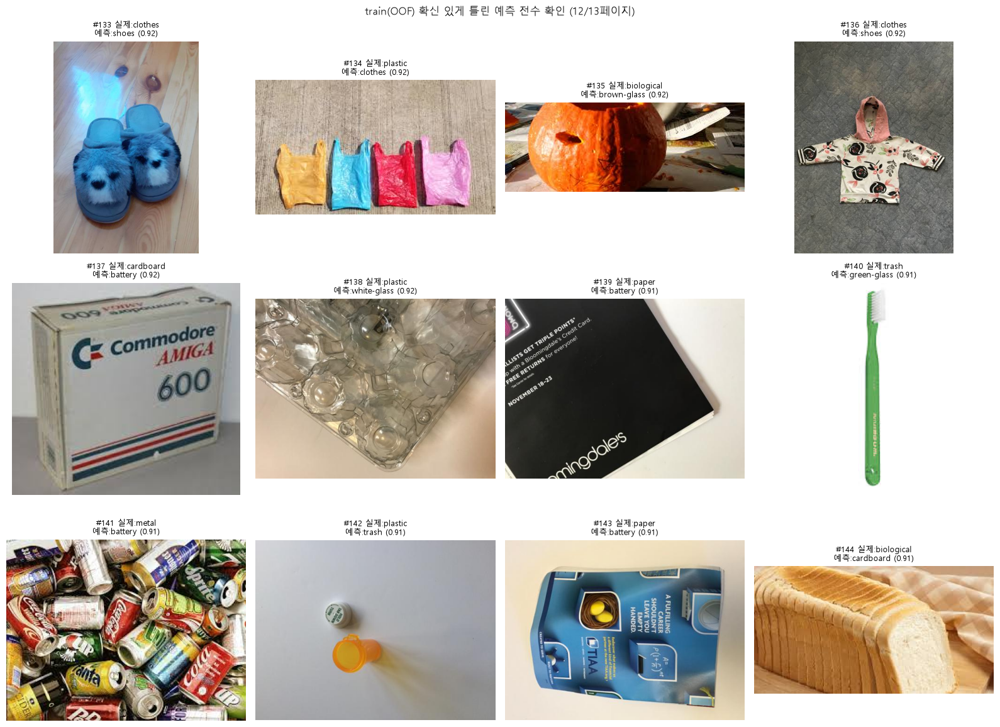

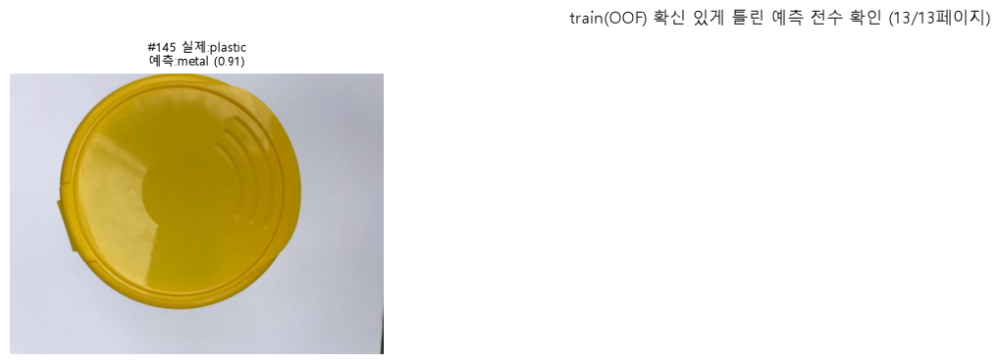

In [30]:
# 위 후보 전체를 이미지로 확인 (한 페이지에 12개씩)
PER_PAGE = 12
n_pages = (len(order) + PER_PAGE - 1) // PER_PAGE
for p in range(n_pages):
    chunk = order[p * PER_PAGE:(p + 1) * PER_PAGE]
    rows = (len(chunk) + 3) // 4
    plt.figure(figsize=(16, 4 * rows))
    for k, pos in enumerate(chunk):
        gi = oof_idx[pos]
        path, _ = label_only.samples[gi]
        rank = p * PER_PAGE + k + 1
        plt.subplot(rows, 4, k + 1)
        plt.imshow(Image.open(path))
        plt.title(f'#{rank} 실제:{class_names[oof_trues[pos]]}\n'
                  f'예측:{class_names[oof_preds[pos]]} ({oof_conf[pos]:.2f})', fontsize=9)
        plt.axis('off')
    plt.suptitle(f'train(OOF) 확신 있게 틀린 예측 전수 확인 ({p + 1}/{n_pages}페이지)')
    plt.tight_layout()
    plt.show()

**5-2 결과 요약 (직접 확인)**

*(아래 내용은 실행 결과 확인 후 채운다)*

## 6. 결과 해석 — Grad-CAM

최종 성능을 낸 그 모델(`best_model`)에서 바로 Grad-CAM을 뽑는다 (해석용 재학습 없음).

In [31]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model.eval()
        self.acts = None
        self.grads = None
        self.handles = [
            target_layer.register_forward_hook(self._save_acts),
            target_layer.register_full_backward_hook(self._save_grads)]

    def _save_acts(self, module, inp, out):
        self.acts = out.detach()
    def _save_grads(self, module, grad_in, grad_out):
        self.grads = grad_out[0].detach()

    def __call__(self, x, class_idx=None):
        # 백본이 freeze된 전이학습 모델에서도 그래프가 만들어지도록 입력에 requires_grad를 켠다
        x = x.clone().requires_grad_(True)
        self.model.zero_grad()
        logits = self.model(x)
        if class_idx is None:
            class_idx = int(logits.argmax(dim=1).item())
        logits[0, class_idx].backward()

        weights = self.grads.mean(dim=(2, 3), keepdim=True)
        heat = (weights * self.acts).sum(dim=1).squeeze(0)
        heat = F.relu(heat)
        if heat.max() > 0:
            heat = heat / heat.max()
        return heat.cpu().numpy(), class_idx

    def remove(self):
        for h in self.handles:
            h.remove()

def overlay_heatmap(heat, img01, alpha=0.4):
    h = torch.from_numpy(heat)[None, None]
    h = F.interpolate(h, size=img01.shape[:2], mode='bilinear', align_corners=False)[0, 0].numpy()
    jet = plt.get_cmap('jet')(h)[:, :, :3]
    return np.clip(img01 * (1 - alpha) + jet * alpha, 0, 1)

target_layer = best_model.features[-1]

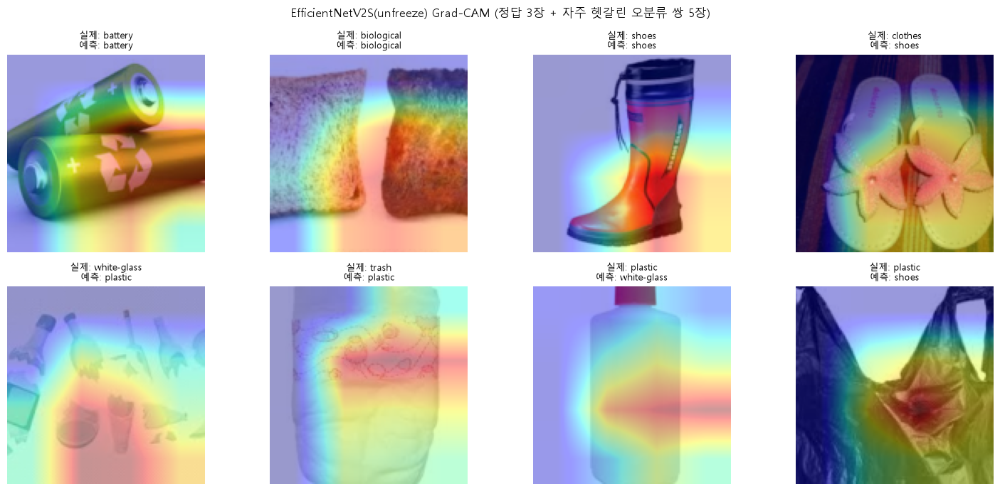

In [32]:
# 무작위 배치 대신, 잘 맞춘 예시 3장 + 위에서 확인한 상위 오분류 쌍 5장을 골라서 확인
def find_one(real_name, pred_name):
    ri, pi = class_names.index(real_name), class_names.index(pred_name)
    idxs = np.where((test_metrics['trues'] == ri) & (test_metrics['preds'] == pi))[0]
    return int(idxs[0]) if len(idxs) > 0 else None

correct_examples = [find_one(c, c) for c in ['battery', 'biological', 'shoes']]
confused_examples = [find_one(real, pred) for _, real, pred in pairs[:5]]
sample_idx = [i for i in (correct_examples + confused_examples) if i is not None][:8]

fig, ax = plt.subplots(2, 4, figsize=(15, 7))
cam = GradCAM(best_model, target_layer)

for k, idx in enumerate(sample_idx):
    i, j = divmod(k, 4)
    x_img, lab = test_set[idx]
    x = x_img.unsqueeze(0).to(device)

    heat, pred_idx = cam(x)
    img01 = denormalize(x_img).permute(1, 2, 0).numpy()

    ax[i, j].imshow(overlay_heatmap(heat, img01))
    ax[i, j].set_title(f'실제: {class_names[lab]}\n예측: {class_names[pred_idx]}', fontsize=9)
    ax[i, j].axis('off')

cam.remove()
plt.suptitle(f'{best_name} Grad-CAM (정답 3장 + 자주 헷갈린 오분류 쌍 5장)')
plt.tight_layout()
plt.show()

## 7. 결론 및 한계

**중복 이미지 반영 (2.ipynb 결과, 셀 8~9)**

완전 동일 중복 22장 제외, 근접 중복 25개 그룹은 같은 split에만 배치. 전체 15,493장으로 재분할(train 10,838 / val 2,318 / test 2,337).

**전처리 · 불균형 대응 방식 비교 (val 기준, 셀 11~16)**

**비율유지 크롭 + WeightedRandomSampler**(val_macro_f1 0.7604)를 채택.

**하이퍼파라미터 튜닝 (셀 13, 20, 22, 24~26)**

- epoch 상한 확장 + 조기 종료(patience 기반), unfreeze 학습률 튜닝(5e-5 채택) + `ReduceLROnPlateau` 스케줄러. 자세한 비교표는 `1_notes.md` 참고.

**모델 비교 — 베이스라인 CNN vs 전이학습(freeze) vs 전이학습(unfreeze) (val 기준, 셀 29 출력)**

| 모델 | val_loss | val_accuracy | val_macro_f1 | val_macro_recall |
|---|---|---|---|---|
| BaselineCNN | 0.8344 | 0.7360 | 0.7095 | 0.7307 |
| EfficientNetV2S(freeze) | 0.5210 | 0.8550 | 0.8009 | 0.8128 |
| **EfficientNetV2S(unfreeze)** | 0.1053 | 0.9728 | **0.9629** | 0.9619 |

**최종(test) 성능 — 셀 31, 32 출력**

- accuracy = 0.9743, macro F1 = 0.9682, macro Recall = 0.9688 — 지금까지 시도한 모든 설정 중 가장 좋은 결과.
- 실험 이력(요약, 전체는 `1_notes.md`): 1차(기본) macro F1 0.7402 → ... → 7차(lr 튜닝+스케줄러) 0.9588 → **8차(cudnn 결정론적 설정 추가) 0.9682**.

**보수적 검토에서 발견·처리한 문제 (사용자 요청으로 진행)**

1. **전처리 비교 셀의 잠재적 버그 — 수정 완료**: `## 4` 모델 비교 셀에서 발견했던 "조기 종료 시 마지막 epoch 값 사용" 버그와 같은 패턴이 `## 2-1` 전처리 비교 셀에도 있었다. `max(history['val_macro_f1'])`로 고쳤다.
2. **재현성(run-to-run 편차) — 확인 완료, 실제로 해결됨**: `torch.backends.cudnn.deterministic = True`, `benchmark = False`를 추가한 뒤 **동일한 노트북을 처음부터 두 번 독립적으로 전체 재실행**했는데, 두 번 모두 val/test 모든 지표(BaselineCNN·freeze·unfreeze 전부)가 **소수점 넷째 자리까지 완전히 동일하게 재현**됐다(예: test macro F1 0.9682가 두 실행 모두 동일). cudnn 설정 이전에는 실행마다 macro F1이 0.9529~0.9588 사이에서 흔들렸던 것과 대조적이다 — **이 설정으로 이 파이프라인의 재현성 문제는 실질적으로 해결됐다고 판단한다.**
3. **라벨 노이즈 점검 — 전수 확인 완료(셀 33~36, 신규)**: held-out(val+test) 4,655장 전체에서 확신도(softmax 확률) 0.9 이상으로 틀린 **59건을 전부** 육안으로 확인했다.
   - **`clothes ↔ shoes` 20건(34%)** 중 **19건이 명백한 라벨 오류**였다 — 운동화·샌들·부츠·로퍼·구두 사진이 `clothes` 폴더에 들어가 있었다. 반대 방향(shoes 폴더에 반바지 사진)이 1건.
   - 유리 색상 클래스(`white/green/brown-glass`) 간 혼동 4건 안팎은 사진상 병 색깔이 라벨과 다르게 보이는 경우로, 조명 때문일 가능성도 있어 확정적이지는 않다.
   - 사진이 아닌 이미지 2건(마스크 클립아트 일러스트, 볼펜 스케치 그림)도 발견했다.
   - 나머지 약 33건은 라벨은 맞지만 재질·색상이 실제로 헷갈리는 진짜 어려운 사례이거나 `cardboard`/`paper`처럼 카테고리 경계 자체가 모호한 경우로 판단된다.
   - **결론**: 실험 내내 반복됐던 `clothes → shoes` 오분류의 상당수(held-out 기준 20건 중 19건)는 **모델의 한계가 아니라 원본 데이터셋의 라벨 오류**였다. 라벨을 직접 고치지는 않았다(전수 재검수·정정은 범위 밖으로 판단, 발견 사실만 기록).

**해결하지 않고 한계로만 남긴 문제**

- **test 표본 수가 작은 클래스 존재**(`brown-glass` 92장, `green-glass` 93장 등): macro 지표가 이런 소수 클래스에서 흔들리기 쉽다 — 구조적 한계이며, 더 많은 데이터 수집 외에는 해결책이 없어 한계로만 기록한다.
- **중복 탐지 커버리지 한계**: `2.ipynb`의 dHash+Hamming+픽셀 검증 기준(Hamming≤5, 픽셀차<0.05)보다 더 많이 변형된 근접 중복은 탐지되지 않았을 수 있다. threshold를 더 느슨하게 하면 칫솔 사례처럼 오탐이 급증하는 것을 이미 확인했으므로(2.ipynb 참고), 실익보다 위험이 크다고 판단해 현재 기준을 유지한다.
- **경미한 과적합**: unfreeze 모델의 train accuracy(~99%)가 val/test(~97%)보다 높지만, val 기준 조기 종료로 최악의 과적합은 피했고 val/test가 함께 개선되는 추세를 학습곡선(셀 27)에서 확인했다 — 추가 조치가 필요한 수준은 아니라고 판단.

**혼동 패턴 및 도메인 해석 (셀 32 Top5, 셀 33~36 라벨 노이즈 전수 점검, 셀 39 Grad-CAM)**

1. `clothes ↔ shoes`: 위에서 확인했듯 대부분 실제 라벨 오류. 남은 소수는 옷 무늬 클로즈업과 신발끈 질감의 시각적 유사성으로 보인다.
2. `metal`/`plastic`/`white-glass`/`brown-glass` 간 혼동: 투명·반사 재질끼리 남아있는 진짜 모델의 한계 — Grad-CAM에서도 병 목/몸통의 반사광 영역에 반응하는 것으로 보아 재질 구분이 이미지만으로 본질적으로 어려운 경우로 판단된다.
3. 실무 시사점: 97%대 정확도는 분리수거 보조 도구로 실제 활용을 검토해볼 만한 수준이다. 다만 원본 데이터셋에 상당수의 라벨 오류(특히 `clothes`/`shoes` 경계)가 확인된 만큼, 실서비스에 적용하려면 데이터셋 자체의 라벨 재검수가 선행되어야 한다.

**하이퍼파라미터 튜닝 요약**

| 하이퍼파라미터 | 튜닝 방식 | 결과 |
|---|---|---|
| 리사이즈 방식 | 정사각형 vs 비율유지 크롭 (val) | 비율유지 크롭 채택 |
| 불균형 대응 | 클래스가중치 vs WeightedRandomSampler (val) | Sampler 채택 |
| epoch 수 | 조기 종료(patience 기반 자동 결정) | 베이스라인/freeze/unfreeze 각각 자동 결정 |
| unfreeze 학습률 | {5e-5, 1e-4, 3e-4} 비교 (val) | 5e-5 채택 |
| 스케줄러 사용 여부 | `ReduceLROnPlateau` 유무 비교 | 낮은 lr에서는 도움, 높은 lr에서는 효과 없음 — 결과적으로 lr 튜닝과 함께 채택 |
| (미실시) 옵티마이저 | Adam과 lr 범위가 크게 달라 공정 비교가 어려워 제외 | Adam만 사용 |

**한계와 개선 방향 (요약)**

- 옵티마이저 튜닝, 계층별 차등 학습률 등 더 세밀한 튜닝은 시도하지 않았다.
- 라벨 오류가 다수 확인된 만큼(특히 `clothes`/`shoes` 경계 19건), 데이터셋 자체의 라벨 재검수·정정이 후속 작업으로 필요하다 — 이를 반영하면 `clothes`/`shoes` 관련 지표가 실제로는 지금보다 더 좋을 가능성이 있다.
- test 표본이 작은 클래스의 macro 지표는 여전히 변동 폭이 있을 수 있다는 점을 감안해서 해석해야 한다.
